# Environment

In [1]:
!git clone https://github.com/Mage-Knight/efficientvit
%cd /kaggle/working/efficientvit
!conda create -n efficientvit python=3.10 -y
!activate efficientvit # for some reason using conda here stopped working

Cloning into 'efficientvit'...
remote: Enumerating objects: 863, done.
remote: Counting objects: 100% (540/540), done.
remote: Compressing objects: 100% (321/321), done.
remote: Total 863 (delta 301), reused 359 (delta 211), pack-reused 323 (from 1)
Receiving objects: 100% (863/863), 196.03 MiB | 24.51 MiB/s, done.
Resolving deltas: 100% (417/417), done.
/kaggle/working/efficientvit
Retrieving notices: ...working... done
Solving environment: done


==> WARNING: A newer version of conda exists. <==
  current version: 23.7.4
  latest version: 24.7.1

Please update conda by running

    $ conda update -n base -c conda-forge conda

Or to minimize the number of packages updated during conda update use

     conda install conda=24.7.1



## Package Plan ##

  environment location: /opt/conda/envs/efficientvit

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-------------

In [2]:
# !conda install -c conda-forge mpi4py openmpi -y

In [3]:
!pip install -r requirements.txt
!pip3 install lightning==2.2.5 torchmetrics==1.4.0.post0 torchvision==0.16.0 torchinfo torch-ema

  Cloning https://github.com/zhijian-liu/torchpack.git (to revision 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5) to /tmp/pip-req-build-w11u0vpz
  Running command git clone --filter=blob:none --quiet https://github.com/zhijian-liu/torchpack.git /tmp/pip-req-build-w11u0vpz
  Running command git rev-parse -q --verify 'sha^3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5'
  Running command git fetch -q https://github.com/zhijian-liu/torchpack.git 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5
  Running command git checkout -q 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5
  Resolved https://github.com/zhijian-liu/torchpack.git to commit 3a5a9f7ac665444e1eb45942ee3f8fc7ffbd84e5
  Preparing metadata (setup.py) ... done
  Cloning https://github.com/alibaba/TinyNeuralNetwork.git to /tmp/pip-req-build-39y1holx
  Running command git clone --filter=blob:none --quiet https://github.com/alibaba/TinyNeuralNetwork.git /tmp/pip-req-build-39y1holx
  Resolved https://github.com/alibaba/TinyNeuralNetwork.git to commit f6703c88

# Imports

In [4]:
import torchvision.transforms as transforms
import torchvision.models as models
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
import torchvision.transforms.v2 as transformsv2
import torchvision.transforms.v2.functional as Fv2

import torch
import torchvision
import random
import math
import os
import gc
import cv2
import PIL
import time
import pickle

from matplotlib.colors import ListedColormap, BoundaryNorm
from transformers import get_cosine_schedule_with_warmup
from tqdm.notebook import tqdm
from copy import deepcopy
from typing import Tuple, Any, Literal
from torch_ema import ExponentialMovingAverage

#EfficientViT
import shutil
from torchinfo import summary
from efficientvit.seg_model_zoo import create_seg_model

# PyTorch
from torch import optim, nn, utils, Tensor
from torchvision.transforms import ToTensor, InterpolationMode, ToPILImage
from torchvision.datasets import ImageFolder
from torch.utils.checkpoint import checkpoint
from torch.utils.data import (
    DataLoader, Dataset, Sampler, BatchSampler, ConcatDataset, random_split
)
from torchvision.transforms.functional import to_pil_image
from torchvision.tv_tensors import Mask
from torchvision.io.image import decode_jpeg, read_file

# Lightning
import lightning as L
from lightning.pytorch.callbacks.early_stopping import EarlyStopping
from lightning.pytorch.loggers import TensorBoardLogger
from torchmetrics.classification import (
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassAccuracy,
    MulticlassF1Score,
    MulticlassJaccardIndex,
    Dice
)
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.utilities import CombinedLoader

## Transformation testing

In [5]:
# import torchvision.transforms.v2 as transformsv2
# from torchvision.io.image import decode_jpeg, read_file
# import torch
# from torchvision.transforms import ToTensor, InterpolationMode, ToPILImage
# import matplotlib.pyplot as plt
# CENTER_CROP_HEIGHT = 960
# CENTER_CROP_WIDTH = 1920
# # Strong augmentation
# strong_transform_st = transformsv2.Compose([
#     transformsv2.ToDtype(torch.uint8, scale=True),
# #     transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
#     transformsv2.RandomResizedCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH), # size=(640, 1280),
#                                    scale=(0.5, 1),
#                                    ratio=(1.75, 2.25), # 3./4., 4./3.
#                                    interpolation=InterpolationMode.BICUBIC,
#                                    antialias=True),
#     transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
# ])

# img = read_file("/kaggle/input/indian-driving-dataset/IDD/idd_seg_part_II_leftImg8bit/train/201/frame0029_leftImg8bit.jpg")
# img = decode_jpeg(img, device="cpu")
# plt.imshow(strong_transform_st(img).permute(1,2,0).numpy())

In [6]:
# plt.imshow(img.permute(1,2,0).numpy())

In [7]:
# # Set up the figure and axes for a 3x3 grid
# fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 8))

# # Flatten the axes array for easy indexing
# axes = axes.flatten()

# for i in range(7):
#     # Display each channel as a subplot
#     ax = axes[i]
#     ax.imshow(tsf[i], cmap='gray',interpolation=None)
#     ax.set_title(f'Channel {i+1}')
#     ax.axis('off')  # Hide the axis

# # Turn off the axes for the empty subplot(s)
# for i in range(7, 9):
#     axes[i].axis('off')

# plt.tight_layout()
# plt.show()

In [8]:
# mask1 = torch.randn((7, 32, 64))
# mask2 = torch.randint(1, 5, size=(7,32,64))
# mask3 = torch.tensor([
#     [[1,2,0,1,2,0,1,2],[0,2,0,0,2,0,0,2],[4,0,0,4,0,0,4,0],[4,0,3,4,0,3,4,0],[4,0,3,4,0,3,4,0],[4,0,3,4,0,3,4,0]],
#     [[1,0,0,1,0,0,1,0],[0,3,0,0,3,0,0,3],[3,3,0,3,3,0,3,3],[0,0,3,0,0,3,0,0],[0,0,3,0,0,3,0,0],[4,0,3,4,0,3,4,0]],
#     [[1,0,4,1,0,4,1,0],[0,0,2,0,0,2,0,0],[3,2,0,3,2,0,3,2],[0,2,3,0,2,3,0,2],[0,0,3,0,0,3,0,0],[5,0,3,5,0,3,5,0]],
#     [[1,0,4,1,0,4,1,0],[0,0,2,0,0,2,0,0],[3,0,0,3,0,0,3,0],[0,1,0,0,1,0,0,1],[0,1,0,0,1,0,0,1],[5,1,0,5,1,0,5,1]],
#     [[2,0,0,2,0,0,2,0],[2,0,0,2,0,0,2,0],[2,0,0,2,0,0,2,0],[0,0,0,0,0,0,0,0],[0,0,0,0,0,0,0,0],[5,0,0,5,0,0,5,0]]])
# mask3 = mask3.permute((2,0,1))
# roi = torch.ones((7,32,64))
# tsf = Fv2.rotate(tsf, 25, InterpolationMode.BILINEAR, fill=0)
# tsf

## Change the 'background' index of segmentation metrics in torchmetrics from 0 to last

In [9]:
from torchmetrics.segmentation import MeanIoU, GeneralizedDiceScore
from torchmetrics.functional.segmentation.mean_iou import _mean_iou_compute
from torchmetrics.functional.segmentation.generalized_dice import _generalized_dice_compute
from torchmetrics.utilities.checks import _check_same_shape

def custom_ignore_background(preds: Tensor, target: Tensor) -> Tuple[Tensor, Tensor]:
    """Ignore the background class in the computation assuming it is the first, index 0."""
    preds = preds[:, :-1] if preds.shape[1] > 1 else preds # change from preds[:, 1:]
    target = target[:, :-1] if target.shape[1] > 1 else target # change from target[:, 1:]
    return preds, target

def _mean_iou_update(
    preds: Tensor,
    target: Tensor,
    num_classes: int,
    include_background: bool = False,
) -> Tuple[Tensor, Tensor]:
    """Update the intersection and union counts for the mean IoU computation."""
    _check_same_shape(preds, target)

    if (preds.bool() != preds).any():  # preds is an index tensor
        preds = torch.nn.functional.one_hot(preds, num_classes=num_classes).movedim(-1, 1)
    if (target.bool() != target).any():  # target is an index tensor
        target = torch.nn.functional.one_hot(target, num_classes=num_classes).movedim(-1, 1)

    if not include_background:
        preds, target = custom_ignore_background(preds, target) # change _ignore_background to custom_ignore_background

    reduce_axis = list(range(2, preds.ndim))
    intersection = torch.sum(preds & target, dim=reduce_axis)
    target_sum = torch.sum(target, dim=reduce_axis)
    pred_sum = torch.sum(preds, dim=reduce_axis)
    union = target_sum + pred_sum - intersection
    return intersection, union

class CustomMeanIoU(MeanIoU):
    def __init__(
        self,
        num_classes: int,
        include_background: bool = True,
        per_class: bool = False,
        **kwargs: Any,
    ) -> None:
        super().__init__(num_classes=num_classes, include_background=include_background, per_class=per_class, **kwargs)

    def update(self, preds: Tensor, target: Tensor) -> None:
        """Update the state with the new data."""
        intersection, union = _mean_iou_update(preds, target, self.num_classes, self.include_background)
        score = _mean_iou_compute(intersection, union, per_class=self.per_class)
        self.score += score.mean(0) if self.per_class else score.mean()

def _generalized_dice_update(
    preds: Tensor,
    target: Tensor,
    num_classes: int,
    include_background: bool,
    weight_type: Literal["square", "simple", "linear"] = "square",
) -> Tensor:
    """Update the state with the current prediction and target."""
    _check_same_shape(preds, target)
    if preds.ndim < 3:
        raise ValueError(f"Expected both `preds` and `target` to have at least 3 dimensions, but got {preds.ndim}.")

    if (preds.bool() != preds).any():  # preds is an index tensor
        preds = torch.nn.functional.one_hot(preds, num_classes=num_classes).movedim(-1, 1)
    if (target.bool() != target).any():  # target is an index tensor
        target = torch.nn.functional.one_hot(target, num_classes=num_classes).movedim(-1, 1)

    if not include_background:
        preds, target = custom_ignore_background(preds, target)  # change _ignore_background to custom_ignore_background

    reduce_axis = list(range(2, target.ndim))
    intersection = torch.sum(preds * target, dim=reduce_axis)
    target_sum = torch.sum(target, dim=reduce_axis)
    pred_sum = torch.sum(preds, dim=reduce_axis)
    cardinality = target_sum + pred_sum

    if weight_type == "simple":
        weights = 1.0 / target_sum
    elif weight_type == "linear":
        weights = torch.ones_like(target_sum)
    elif weight_type == "square":
        weights = 1.0 / (target_sum**2)
    else:
        raise ValueError(
            f"Expected argument `weight_type` to be one of 'simple', 'linear', 'square', but got {weight_type}."
        )

    w_shape = weights.shape
    weights_flatten = weights.flatten()
    infs = torch.isinf(weights_flatten)
    weights_flatten[infs] = 0
    w_max = torch.max(weights, 0).values.repeat(w_shape[0], 1).T.flatten()
    weights_flatten[infs] = w_max[infs]
    weights = weights_flatten.reshape(w_shape)

    numerator = 2.0 * intersection * weights
    denominator = cardinality * weights
    return numerator, denominator  # type:ignore[return-value]        

class CustomGeneralizedDiceScore(GeneralizedDiceScore):
    def __init__(
        self,
        num_classes: int,
        include_background: bool = True,
        per_class: bool = False,
        weight_type: Literal["square", "simple", "linear"] = "square",
        **kwargs: Any,
    ) -> None:
        super().__init__(num_classes=num_classes, include_background=include_background, per_class=per_class, weight_type=weight_type, **kwargs)

    def update(self, preds: Tensor, target: Tensor) -> None:
        """Update the state with new data."""
        numerator, denominator = _generalized_dice_update(
            preds, target, self.num_classes, self.include_background, self.weight_type
        )
        self.score += _generalized_dice_compute(numerator, denominator, self.per_class).sum(dim=0)
        self.samples += preds.shape[0]

## Install RandAugment implementation for semantic segmentation

In [10]:
class CustomRandAug(nn.Module):
    # Minimum value for posterize (0 in EfficientNet implementation)
    POSTERIZE_MIN = 1
    WARP_PARAMS = {}

    def solarize_add(x, v):
        x = torch.clone(x)  # Clone to avoid modifying the original tensor in-place
        mask = x < 128
        x[mask] = torch.clamp(x[mask] + int(v), 0, 255)
        return x

    OP_FUNCTIONS = {
        # Each op takes an image x and a level v and returns an augmented image.
        # image is in torch format with range [0,1] instead of PIL format with range [0,255]
        "auto_contrast": lambda x, _: Fv2.autocontrast(x),
        "equalize": lambda x, _: Fv2.equalize(x),
        "invert": lambda x, _: Fv2.invert(x),
        "rotate": lambda x, v: Fv2.rotate(x, angle=v, **CustomRandAug.WARP_PARAMS),
        "posterize_inc": lambda x, v: Fv2.posterize(x, bits=max(CustomRandAug.POSTERIZE_MIN, 4 - int(v))),
        "solarize_inc": lambda x, v: Fv2.solarize(x, threshold=1-v),
        "solarize_add": lambda x, v: CustomRandAug.solarize_add(x, v),
        "color_inc": lambda x, v: Fv2.adjust_saturation(x, saturation_factor=1+v),
        "contrast_inc": lambda x, v: Fv2.adjust_contrast(x, contrast_factor=1+v),
        "brightness_inc": lambda x, v: Fv2.adjust_brightness(x, brightness_factor=1+v),
        "sharpness_inc": lambda x, v: Fv2.adjust_sharpness(x, sharpness_factor=1+v),
        "shear_x": lambda x, v: Fv2.affine(x, angle=0, translate=[0, 0], scale=1, shear=[v, 0], **CustomRandAug.WARP_PARAMS),
        "shear_y": lambda x, v: Fv2.affine(x, angle=0, translate=[0, 0], scale=1, shear=[0, v], **CustomRandAug.WARP_PARAMS),
        "trans_x": lambda x, v: Fv2.affine(x, angle=0, translate=[v, 0], scale=1, shear=0, **CustomRandAug.WARP_PARAMS),
        "trans_y": lambda x, v: Fv2.affine(x, angle=0, translate=[0, v], scale=1, shear=0, **CustomRandAug.WARP_PARAMS),
    }

    OP_RANGES = {
        # Ranges for each op in the form of a (min, max, negate).
        "auto_contrast": (0, 1, False),
        "equalize": (0, 1, False),
        "invert": (0, 1, False),
        "rotate": (0.0, 30.0, True),
        "posterize_inc": (0, 4, False),
        "solarize_inc": (0, 255, False),
        "solarize_add": (0, 110, False),
        "color_inc": (0, 0.9, True), #
        "contrast_inc": (0, 0.9, True),
        "brightness_inc": (0, 0.9, True),
        "sharpness_inc": (0, 0.9, True),
        "shear_x": (0.0, math.degrees(math.atan(0.3)), True), # previous range (0.0, 0.3)
        "shear_y": (0.0, math.degrees(math.atan(0.3)), True),
        "trans_x": (0.0, 0.45, True),
        "trans_y": (0.0, 0.45, True),
    }

    RANDAUG_OPS = [
        # RandAugment list of operations using "increasing" transforms.
        # Affine operations turned off due to usage of cutmix and classmix
        "auto_contrast",
        "equalize",
        #"invert",
        "posterize_inc",
        "solarize_inc",
        "solarize_add",
        "color_inc",
        "contrast_inc",
        "brightness_inc",
        "sharpness_inc"
    ]
    
    RANDAUG_OPS_AFFINE = [
        # RandAugment list of operations using "increasing" transforms.
        "auto_contrast",
        "equalize",
        #"invert",
        "rotate",
        "posterize_inc",
        "solarize_inc",
        "solarize_add",
        "color_inc",
        "contrast_inc",
        "brightness_inc",
        "sharpness_inc",
        "shear_x",
        "shear_y",
        "trans_x",
        "trans_y",
    ]

    AFFINE_OPS = [
        "rotate","shear_x","shear_y","trans_x","trans_y"
    ]
    
    def __init__(self, use_affine=True, magnitude=0.9, magnitude_std=0.05, n_ops=2, prob=0.5,
                 fill=(128, 128, 128), ignore_value=26, mask_format='discrete'):
        super().__init__()
        if use_affine:
            self.aug_ops_list = CustomRandAug.RANDAUG_OPS_AFFINE
        else:
            self.aug_ops_list = CustomRandAug.RANDAUG_OPS

        if mask_format!="discrete" and mask_format!="logits":
            raise Exception(f"Unknown mask format: {mask_format}")

        self.mask_format = mask_format
        self.magnitude = magnitude
        self.magnitude_std = magnitude_std
        self.n_ops = n_ops
        self.prob = prob
        self.fill = fill
        self.ignore_value = ignore_value

    def forward(self, *args): # possible *args structure: 
        images = args[0]      # - (mandatory) images
        if len(args) >= 2:    # - (optional) masks
            masks = args[1]   # - (possible if mask_format=="discrete") pixel_confidence
        if len(args) == 3:    # - (will be added automatically if mask_format=="logits") roi_mask
            pix_conf = args[2]
            assert isinstance(pix_conf, Mask), "The received pix_conf tensor is not of tv_tensors.Mask type"
            assert images.device == pix_conf.device, f"Images and pix_conf are not on the same device ({images.device} and {pix_conf.device})"
        elif len(args) > 3:
            raise Exception(f"Unsupported input length: {len(args)}")
        assert isinstance(masks, Mask), "The received mask tensor is not of tv_tensors.Mask type"
        assert images.device == masks.device, f"Images and masks are not on the same device ({images.device} and {masks.device})"
        
        self.overall_device = images.device
        if len(args) != 3:
            images, masks = self.rand_augment_both(images, masks)
        else:
            images, masks, pix_conf = self.rand_augment_both(images, masks, pix_conf)
    
        if len(args) == 3:
            return images.to(self.overall_device), Mask(masks).to(self.overall_device) , Mask(pix_conf).to(self.overall_device)
        elif self.mask_format != "logits":
            return images.to(self.overall_device), Mask(masks).to(self.overall_device)
        else:
            return images.to(self.overall_device), Mask(masks).to(self.overall_device), Mask(self.roi_mask).to(self.overall_device)

    def rand_augment_both(self, images, *args):
        """
        Applies random augmentation to an image.
        Modified implementation from https://github.com/RolandGao/RegSeg/blob/main/augment.py#L141.
        Automatically uses 'inc1', which means that it is implemented in such way, that severity
        of all augmentations increase with the magnitude. Also magnitude is in range(0,1) instead of
        range(0,10) like in timm library implementation.
        """

        batch_size = images.shape[0]
        if self.magnitude_std > 0:  # Add random magnitude option
            magnitude = np.clip(np.random.normal(self.magnitude, self.magnitude_std, batch_size), 0, 1)
        else:
            magnitude = np.full(batch_size, magnitude)

        if len(args) >= 1:
            masks = args[0]
        if len(args) == 2:
            pix_conf = args[1]
            
        if self.mask_format=="logits":
            self.roi_mask = torch.ones(
                tuple(np.array(masks.shape)[[0, 2, 3]])
            ).to(self.overall_device)
        
        for i in range(batch_size):
            for aug in random.sample(self.aug_ops_list, int(self.n_ops)):
                if self.mask_format == "logits":
                    images[i], masks[i], self.roi_mask[i] = self.apply_op_both(
                        (images[i], masks[i], self.roi_mask[i]), aug, magnitude[i]
                    )
                elif len(args) == 2:
                    images[i], masks[i], pix_conf[i] = self.apply_op_both(
                        (images[i], masks[i], pix_conf[i]), aug, magnitude[i]
                    )
                else:
                    images[i], masks[i] = self.apply_op_both((images[i], masks[i]), aug, magnitude[i])
        if len(args) == 2:
            return images, masks, pix_conf
        else:
            return images, masks
    
    def apply_op_both(self, inputs, aug, magnitude):
        """Apply the selected op to image with given probability and magnitude."""
        # The magnitude is converted to an absolute value v for an op (some ops use -v or v)
        assert 0 <= magnitude <= 1
        assert aug in CustomRandAug.OP_RANGES and aug in CustomRandAug.RANDAUG_OPS_AFFINE, "unknown op " + aug
        if len(inputs)==2:
            img, mask = inputs
        elif len(inputs)==3:
            img, mask, supplem_mask = inputs
        else:
            raise Exception(f"Unsupported input length: {len(inputs)}")
        if self.prob < 1 and random.random() > self.prob:
            if len(inputs)==2:
                return img, mask
            else:
                return img, mask, supplem_mask
        else:
            min_v, max_v, negate = CustomRandAug.OP_RANGES[aug]
            v = magnitude * (max_v - min_v) + min_v
            v = -v if negate and random.random() > 0.5 else v
            # Image augmentation
            CustomRandAug.WARP_PARAMS["fill"] = self.fill
            CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.BILINEAR
            img = CustomRandAug.OP_FUNCTIONS[aug](img, v)
            if aug in CustomRandAug.AFFINE_OPS:
                if self.mask_format!="logits":
                    # Discrete mask augmentation
                    CustomRandAug.WARP_PARAMS["fill"] = self.ignore_value
                    CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.NEAREST
                    mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(mask), v)
                    if len(inputs)==3:
                        # Confidence augmentation
                        CustomRandAug.WARP_PARAMS["fill"] = 0
                        CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.NEAREST
                        supplem_mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(supplem_mask), v) # pix_conf
                else:
                    # Logit mask augmentation
                    CustomRandAug.WARP_PARAMS["fill"] = 0
                    CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.BILINEAR
                    mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(mask), v)
                    # Region of interest mask augmentation
                    CustomRandAug.WARP_PARAMS["interpolation"] = InterpolationMode.NEAREST
                    supplem_mask = CustomRandAug.OP_FUNCTIONS[aug](Mask(supplem_mask), v) # roi_mask
            if self.mask_format!="logits" and len(inputs) == 3:
                return img, mask, supplem_mask
            else:
                return img, mask

# Const variables

In [11]:
BATCH_SIZE_ST = 10 # 32 -> 16 (last)
BATCH_SIZE_SST = 2 # 8 / 6 -> 4 (last)
UNLAB_MULT = 4 # 4 / 5 -> 4 (last)
MEAN_TRN = np.load("/kaggle/input/efficientvit-checkpoint/channel_mean.npy")
STD_TRN = np.load("/kaggle/input/efficientvit-checkpoint/channel_std.npy")
RAND_CONST = 10
# NEW_HEIGHT, NEW_WIDTH = 224, 448
# NEW_HEIGHT_FT, NEW_WIDTH_FT = 288, 576
# size 512 x 1024 takes approx. 10 minutes per epoch
CENTER_CROP_HEIGHT = 960
CENTER_CROP_WIDTH = 1920
NEW_HEIGHT, NEW_WIDTH = 608, 1216 # 416, 832   # 256, 512 
NEW_HEIGHT_FT, NEW_WIDTH_FT = 608, 1216  # 256, 512
DECAY_VAL = 0.99 # 0.9999 if one teacher

LOW_LEVEL_MAPPING = [
    'road',
    'parking/drivable fallback',
    'sidewalk',
    'non-drivable fallback/rail track',
    'person/animal',
    'rider',
    'motorcycle',
    'bicycle',
    'autorickshaw',
    'car',
    'truck',
    'bus',
    'caravan/trailer/vehicle fallback',
    'curb',
    'wall',
    'fence',
    'guard rail',
    'billboard',
    'traffic sign',
    'traffic light',
    'pole/polegroup',
    'obs-str-bar-fallback',
    'building',
    'bridge/tunnel',
    'vegetation',
    'sky/fallback background',
    'unlabeled/out of roi' # label 26, not used during training
]
HIGH_LEVEL_MAPPING = [
    'drivable',
    'non-drivable',
    'living things',
    'vehicles',
    'road side objects',
    'far objects',
    'sky',
    'unlabeled/out of roi' # label 7 not used during training
]
HIGH_NUM_CLASSES = len(HIGH_LEVEL_MAPPING) - 1
LOW_NUM_CLASSES = len(LOW_LEVEL_MAPPING) - 1

# # Define a list of distinct colors (excluding black and white)
# colors = [
#     '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', 
#     '#e377c2', '#7f7f7f', '#bcbd22', '#17becf', '#1a55FF', '#55a8ff', 
#     '#6e6e6e', '#85a3e0', '#296e01', '#28ed28', '#848484', '#adf802', 
#     '#ffaa00', '#d35400', '#c0392b', '#bdc3c7', '#7f8c8d', '#999999', 
#     '#f39c12', '#f5b041', '#dc7633', '#6e2c00'
# ]

colors = [
    "#33cc33", # light green
    "#663300", # brown
    "#cc0000", # red
    "#ffff00", # yellow
    "#660066", # purple
    "#1f77b4", # blue
    "#66ffff", # light blue
    "#808080", # gray
]

# Ensure there are enough colors for each class
assert len(colors) >= len(HIGH_LEVEL_MAPPING), "Not enough colors for each class"

def hex_to_rgb(hex_color):
    return tuple(int(hex_color[i:i+2], 16) / 255. for i in (1, 3, 5))  # skip the '#'

RGB_COLORS = [hex_to_rgb(color) for color in colors]

# Create a colormap from the list of colors
HIGH_CMAP = ListedColormap(RGB_COLORS[:len(HIGH_LEVEL_MAPPING)])
boundaries_high = np.arange(-0.5, len(HIGH_LEVEL_MAPPING) + 0.5, 1)  # Setting boundaries between labels
HIGH_NORM = BoundaryNorm(boundaries_high, HIGH_CMAP.N, clip=True)  # Create the norm

LOW_CMAP = plt.get_cmap('tab20', LOW_NUM_CLASSES + 1)
boundaries_low = np.arange(-0.5, len(LOW_LEVEL_MAPPING) + 0.5, 1)  # Setting boundaries between labels
LOW_NORM = BoundaryNorm(boundaries_low, LOW_CMAP.N, clip=True)  # Create the norm
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CLASS_WEIGHTS = torch.tensor(np.load("/kaggle/input/efficientvit-checkpoint/class_weights.npy"))

# Reproducibility

In [12]:
# Worker initialization function for data loaders (simplest approach)
def seed_worker(worker_id):
    worker_seed = (torch.initial_seed() + worker_id) % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g_train = torch.Generator().manual_seed(RAND_CONST)
g_val = torch.Generator().manual_seed(RAND_CONST + 1)
g_test = torch.Generator().manual_seed(RAND_CONST + 2)

# Seed the RNG for all devices (both CPU and CUDA)
torch.manual_seed(RAND_CONST)
# Set python seed
random.seed(RAND_CONST)
# Set numpy seed
np.random.seed(RAND_CONST)
# Force cuDNN to deterministically select an algorithm
# *possibly at the cost of reduced performance
# torch.backends.cudnn.benchmark = False # turned off to achieve the best results
# Configure PyTorch to use deterministic algorithms
# torch.use_deterministic_algorithms(True) (involves env. variables, so not used)

# Model definition

In [13]:
# semantic segmentation
from efficientvit.models.efficientvit.seg import SegHead
from efficientvit.models.efficientvit.seg import EfficientViTSeg
from efficientvit.models.efficientvit.backbone import efficientvit_backbone_b1, EfficientViTBackbone, EfficientViTLargeBackbone
from efficientvit.models.utils import build_kwargs_from_config

class EfficientViTSegMod(EfficientViTSeg):
    def __init__(self, backbone: EfficientViTBackbone or EfficientViTLargeBackbone, head: SegHead) -> None:
        super().__init__(backbone, head)
        self.enlarge = nn.Upsample(scale_factor=(8,8), mode='bicubic')
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feed_dict = self.backbone(x)
        feed_dict = self.head(feed_dict)
#         return feed_dict["segout"]
        return self.enlarge(feed_dict["segout"])

def efficientvit_seg_b1(dataset: str, **kwargs) -> EfficientViTSegMod:
    backbone = efficientvit_backbone_b1(**kwargs)

    if dataset == "cityscapes":
        head = SegHead(
            fid_list=["stage4", "stage3", "stage2"],
            in_channel_list=[256, 128, 64],
            stride_list=[32, 16, 8],
            head_stride=8,
            head_width=64,
            head_depth=3,
            expand_ratio=4,
            middle_op="mbconv",
            final_expand=4,
            n_classes=HIGH_NUM_CLASSES,
            **build_kwargs_from_config(kwargs, SegHead),
        )
    else:
        raise NotImplementedError
    model = EfficientViTSegMod(backbone, head)
    return model

from efficientvit.models.efficientvit import (
    EfficientViTSeg,
    efficientvit_seg_b0,
    efficientvit_seg_b1,
    efficientvit_seg_b2,
#     efficientvit_seg_b3,
#     efficientvit_seg_l1,
#     efficientvit_seg_l2,
)
from efficientvit.models.nn.norm import set_norm_eps
from efficientvit.models.utils import load_state_dict_from_file

__all__ = ["create_seg_model"]

REGISTERED_SEG_MODEL: dict[str, dict[str, str]] = {
    "cityscapes": {
        "b0": "assets/checkpoints/seg/cityscapes/b0.pt",
        "b1": "assets/checkpoints/seg/cityscapes/b1.pt",
        "b2": "assets/checkpoints/seg/cityscapes/b2.pt",
#         "b3": "assets/checkpoints/seg/cityscapes/b3.pt",
        ################################################
#         "l1": "assets/checkpoints/seg/cityscapes/l1.pt",
#         "l2": "assets/checkpoints/seg/cityscapes/l2.pt",
    },
#     "ade20k": {
#         "b1": "assets/checkpoints/seg/ade20k/b1.pt",
#         "b2": "assets/checkpoints/seg/ade20k/b2.pt",
#         "b3": "assets/checkpoints/seg/ade20k/b3.pt",
        ################################################
#         "l1": "assets/checkpoints/seg/ade20k/l1.pt",
#         "l2": "assets/checkpoints/seg/ade20k/l2.pt",
#     },
}


def create_seg_model(
    name: str, dataset: str, pretrained=True, weight_url: str or None = None, **kwargs
) -> EfficientViTSegMod:
    model_dict = {
        "b0": efficientvit_seg_b0,
        "b1": efficientvit_seg_b1,
        "b2": efficientvit_seg_b2,
#         "b3": efficientvit_seg_b3,
        #########################
#         "l1": efficientvit_seg_l1,
#         "l2": efficientvit_seg_l2,
    }

    model_id = name.split("-")[0]
    if model_id not in model_dict:
        raise ValueError(f"Do not find {name} in the model zoo. List of models: {list(model_dict.keys())}")
    else:
        model = model_dict[model_id](dataset=dataset, **kwargs)

    if model_id in ["l1", "l2"]:
        set_norm_eps(model, 1e-7)

    if pretrained:
        weight_url = weight_url or REGISTERED_SEG_MODEL[dataset].get(name, None)
        if weight_url is None:
            raise ValueError(f"Do not find the pretrained weight of {name}.")
        else:
            weight = load_state_dict_from_file(weight_url)
            model.load_state_dict(weight)
    return model

# Model creation
model_b1 = create_seg_model(
  name="b1", dataset="cityscapes", weight_url="assets/checkpoints/seg/cityscapes/b1.pt"
)
model_b1.head = SegHead(
    fid_list=["stage4", "stage3", "stage2"],
    in_channel_list=[256, 128, 64],
    stride_list=[32, 16, 8],
    head_stride=8,
    head_width=64,
    head_depth=3,
    expand_ratio=4,
    middle_op="mbconv",
    final_expand=4,
    n_classes=HIGH_NUM_CLASSES
)

In [14]:
model_b1

EfficientViTSeg(
  (backbone): EfficientViTBackbone(
    (input_stem): OpSequential(
      (op_list): ModuleList(
        (0): ConvLayer(
          (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
          (norm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (act): Hardswish()
        )
        (1): ResidualBlock(
          (main): DSConv(
            (depth_conv): ConvLayer(
              (conv): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
              (norm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (act): Hardswish()
            )
            (point_conv): ConvLayer(
              (conv): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (norm): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            )
          )
          (shortcut): Identity

In [15]:
batch_size = 1
summary(model_b1, input_size=(1, 3, 416, 768))

Layer (type:depth-idx)                                            Output Shape              Param #
EfficientViTSeg                                                   [1, 7, 52, 96]            --
├─EfficientViTBackbone: 1-1                                       [1, 256, 13, 24]          --
│    └─OpSequential: 2-1                                          [1, 16, 208, 384]         --
│    │    └─ModuleList: 3-1                                       --                        928
│    └─ModuleList: 2-2                                            --                        --
│    │    └─OpSequential: 3-2                                     [1, 32, 104, 192]         13,888
│    │    └─OpSequential: 3-3                                     [1, 64, 52, 96]           86,528
│    │    └─OpSequential: 3-4                                     [1, 128, 26, 48]          756,864
│    │    └─OpSequential: 3-5                                     [1, 256, 13, 24]          3,785,728
├─SegHead: 1-2          

In [16]:
# !python demo_seg_model.py --image_path assets/fig/068726_leftImg8bit.png --dataset cityscapes --crop_size 1024 --model b1

# Dataset

In [17]:
class IDD_Dataset(Dataset):
    def __init__(self, root_dir, parts = ['I', 'II'], splits = ['train', 'val'], hierarchy="low"):
        self.root_dir_img = root_dir + "/IDD"
        self.root_dir_mask = root_dir + ("/IDD" if hierarchy == "low" else "/high_level_labels")
        self.data_paths = []
        self.data_shapes = []
        self.is_test_set = splits == ['test']
        self.hierarchy = hierarchy

        for part in parts:
            if not self.is_test_set:
                for split in splits:
                    mask_dir = os.path.join(
                        self.root_dir_mask,
                        f'idd_seg_part_{part}_gtFine' + "_high" if hierarchy=="high" else "",
                        split
                    )
                    # img_dir = os.path.join(root_dir, f'idd_seg_part_{part}_leftImg8bit', split)
                    for folder_num in os.listdir(mask_dir):
                        for mask_file in os.listdir(os.path.join(mask_dir, folder_num)):
                            if mask_file.endswith('_gtFine_polygons.npz'):
                                starting_part = mask_file.replace('_gtFine_polygons.npz', '')
                                # Obtaining image shape
                                img_path = os.path.join(
                                    self.root_dir_img,
                                    f'idd_seg_part_{part}_leftImg8bit',
                                    split,
                                    folder_num,
                                    f'{starting_part}_leftImg8bit.jpg'
                                )
                                img = read_file(img_path)
                                img = decode_jpeg(img, device="cpu")
                                (height, width) = img.shape[1:] # Get the image size
#                                 img = PIL.Image.open(img_path)
#                                 width, height = img.size # Get the image size
                                self.data_shapes.append((height, width))
                                self.data_paths.append((part, split, folder_num, starting_part))
            else:
                for split in splits:
                    img_dir = os.path.join(
                        self.root_dir_img,
                        f'idd_seg_part_{part}_leftImg8bit',
                        split
                    )
                    for folder_num in os.listdir(img_dir):
                        for img_file in os.listdir(os.path.join(img_dir, folder_num)):
                            if img_file.endswith('_leftImg8bit.jpg'):
                                starting_part = img_file.replace('_leftImg8bit.jpg', '')
                                # Obtaining image shape
                                img_path = os.path.join(
                                    self.root_dir_img,
                                    f'idd_seg_part_{part}_leftImg8bit',
                                    split,
                                    folder_num,
                                    f'{starting_part}_leftImg8bit.jpg'
                                )
                                img = read_file(img_path)
                                img = decode_jpeg(img, device="cpu")
                                (height, width) = img.shape[1:] # Get the image size
#                                 img = PIL.Image.open(img_path)
#                                 width, height = img.size # Get the image size
                                self.data_shapes.append((height, width))
                                self.data_paths.append((part, split, folder_num, starting_part))

        self.data_shapes = np.array(self.data_shapes)

    def __len__(self):
        return len(self.data_paths)

    def __getitem__(self, idx):
        part, split, folder_num, starting_part = self.data_paths[idx]

        if not self.is_test_set:
            mask_path = os.path.join(
                self.root_dir_mask,
                f'idd_seg_part_{part}_gtFine' + "_high" if self.hierarchy=="high" else "",
                split,
                folder_num,
                f'{starting_part}_gtFine_polygons.npz'
            )
            mask = np.load(mask_path)['masks']
        else:
            mask = np.array([-1])
        
        img_path = os.path.join(
            self.root_dir_img,
            f'idd_seg_part_{part}_leftImg8bit',
            split,
            folder_num,
            f'{starting_part}_leftImg8bit.jpg'
        )
        img = read_file(img_path)
        img = decode_jpeg(img, device="cpu")
        # Return Image: C x H x W, Mask: H x W
        return img, Mask(torch.from_numpy(mask))
        # Changed approach below to decoding jpeg because of time consumption
#         img = PIL.Image.open(img_path) 
#         img = np.array(img)
        # Return Image: C x H x W, Mask: H x W
#         return torch.from_numpy(img).permute((2,0,1)), Mask(torch.from_numpy(mask))
    
    def image_shapes_quantity(self, check_idx="all", print_flag=False):
        indices_by_shape = {}
        if type(check_idx)!=str:
            check_idx = np.array(check_idx)
        for idx, (height, width) in enumerate(self.data_shapes):
            if type(check_idx)==str and check_idx=="all":
                indices_by_shape.setdefault((height, width), []).append(idx)
            elif idx in check_idx:
                renumb_idx = np.where(check_idx == idx)[0][0]
                indices_by_shape.setdefault((height, width), []).append(renumb_idx)

        for key, elements in indices_by_shape.items():
            indices_by_shape[key] = np.array(elements)

        if not print_flag:
            return indices_by_shape
        else:
            for key, elements in indices_by_shape.items():
                print(f"Amount (ratio) of {key} sized elements: {len(elements)} ({len(elements)/len(self)})")


class SameShapeSampler(Sampler):
    def __init__(self, data_source, batch_size, generator=None):
        self.data_source = data_source
        self.batch_size = batch_size
        self.generator = generator
        self.indices_by_shape = data_source.image_shapes_quantity()

    def __iter__(self):
        all_batches = []
        for _, indices in self.indices_by_shape.items(): # shape not used
            shuffled_indices_idx = torch.randperm(len(indices), generator=self.generator)
            shuffled_indices = indices[shuffled_indices_idx]
            for i in range(0, len(shuffled_indices) - self.batch_size + 1, self.batch_size):
                batch = shuffled_indices[i:i+self.batch_size]
                all_batches.append(batch)

        all_batches = np.array(all_batches)
        shuffled_batches_idx = torch.randperm(all_batches.shape[0], generator=self.generator)
        return iter(all_batches[shuffled_batches_idx,:].flatten())

    def __len__(self):
        return sum((len(indices) - len(indices) % self.batch_size) for indices in self.indices_by_shape.values())


class SameShapeBatchSampler(Sampler):
    def __init__(self, data_source, batch_size, shuffle, drop_last, generator=None):
        self.data_source = data_source
        self.batch_size = batch_size
        self.generator = generator
        self.shuffle = shuffle
        self.drop_last = drop_last
        if isinstance(data_source, IDD_Dataset):
            self.indices_by_shape = data_source.image_shapes_quantity()
        elif isinstance(data_source, torch.utils.data.ConcatDataset):
            cum_data_size = 0
            self.indices_by_shape = {}
            for dataobj in data_source.datasets:
                if isinstance(dataobj, torch.utils.data.Subset):
                    new_idx = dataobj.dataset.image_shapes_quantity(check_idx=dataobj.indices)
                elif isinstance(dataobj, IDD_Dataset):
                    new_idx = dataobj.image_shapes_quantity()
                else:
                    raise Exception(f"Unknown dataobj type: {type(dataobj)}")
                new_idx = {key: value + cum_data_size for key, value in new_idx.items()}
                self.indices_by_shape.update(new_idx)
                cum_data_size += len(dataobj)
        elif isinstance(data_source, torch.utils.data.dataset.Subset):
            self.indices_by_shape = data_source.dataset.image_shapes_quantity(check_idx=data_source.indices)
        else:
            raise Exception(f"Unknown data_source type: {type(data_source)}")


    def __iter__(self):
        all_batches = []
        if not self.drop_last:
            resid_batches = []
        for _, indices in self.indices_by_shape.items(): # shape not used
            if self.shuffle:
                shuffled_indices_idx = torch.randperm(len(indices), generator=self.generator)
                indices = indices[shuffled_indices_idx]
            for i in range(0, len(indices) - self.batch_size + 1, self.batch_size):
                batch = indices[i:i+self.batch_size]
                all_batches.append(batch)
            if not self.drop_last:
                resid_batches.append(indices[-int(len(indices) % self.batch_size):])

#         all_batches = np.array(all_batches)
        if self.shuffle:
            shuffled_batches_idx = torch.randperm(len(all_batches), generator=self.generator)
#             all_batches = all_batches[shuffled_batches_idx,:]
            all_batches = [all_batches[i] for i in shuffled_batches_idx]
            if not self.drop_last:
                shuffled_resid_batches_idx = torch.randperm(len(resid_batches), generator=self.generator)
                resid_batches = [resid_batches[i] for i in shuffled_resid_batches_idx]
        
        if not self.drop_last:
            all_batches += resid_batches
#             all_batches = np.vstack((all_batches, resid_batches)) # uncomplete batches go to the end
        
        for batch_idx in range(len(all_batches)):
            yield all_batches[batch_idx]
#             yield all_batches[batch_idx,:]

    def __len__(self):
        if self.drop_last:
            return sum((len(indices) // self.batch_size) for indices in self.indices_by_shape.values())
        else:
            return sum((len(indices) // self.batch_size) + (1 if len(indices) % self.batch_size != 0 else 0) for indices in self.indices_by_shape.values())
            


def apply_model_and_show_results(model, image, new_height, new_width, level_mapping=HIGH_LEVEL_MAPPING,
                                 cmap=HIGH_CMAP, norm=HIGH_NORM, real_mask=None, transform=None):

    # Ensure model is in evaluation mode
    model.eval()
    if transform is None:
        transform = transformsv2.Compose([
            transformsv2.ToDtype(torch.float32, scale=True),
            transformsv2.Resize((NEW_HEIGHT, NEW_WIDTH), antialias=True)
        ])

    if real_mask is not None:
        image, real_mask = transform(image.unsqueeze(0), Mask(real_mask.unsqueeze(0)))
    else:
        image = transform(image.unsqueeze(0))

    original_height, original_width = image.shape[2:4]
    # Resize image
#     image_resized = transforms.functional.resize(
#         input_image.squeeze(0), size=(new_height, new_width),
#         interpolation=InterpolationMode.BICUBIC,
#         antialias=False
#     ) # shape: C x H x W

    # Apply model to image
    with torch.no_grad():
        logits = model(image.to(DEVICE)) # add batch_size=1

    # Resize predicted mask back to original size
    logits = Fv2.resize(
        logits.detach().cpu()[0], size=(original_height, original_width),
        interpolation=InterpolationMode.BICUBIC,
        antialias=True
    ) # shape: num_classes x H x W

    # Get the predicted class for each pixel
    predicted = torch.argmax(logits, 0).numpy() # shape: H x W

    # Display the overlay
    fig, axs = plt.subplots(3 if real_mask is not None else 2, 1, figsize=(25, 15))

    image = image.squeeze(0)
    axs[0].imshow(image.permute((1,2,0)))
    axs[0].set_title('Image')
    axs[0].axis('off')
    
    axs[1].imshow(image.permute((1,2,0)), cmap='gray', interpolation='none')
    axs[1].imshow(predicted, cmap=cmap, norm=norm, alpha=0.5, interpolation='none')
    axs[1].set_title('Predicted mask')
    axs[1].axis('off')

    if real_mask is not None:
        axs[2].imshow(image.permute((1,2,0)), cmap='gray', interpolation='none')
        axs[2].imshow(real_mask.squeeze((0,1)), cmap=cmap, norm=norm, alpha=0.5, interpolation='none')
        axs[2].set_title('Real mask')
        axs[2].axis('off')

        # Create legend
        present_classes = np.unique(real_mask.squeeze(0))
        patches = [mpatches.Patch(color=cmap(i), label=f"ID: {i}, Name: {level_mapping[i]}") for i in present_classes]
        plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

    plt.show()
#     return real_mask.squeeze((0,1))

# Augmentations

In [18]:
# pipe_augment_test = transformsv2.Compose([
#     CustomRandAug(n_ops=14), # automatically converts from PIL format back to tensor and tv_tensors.Mask format
#     transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
# ])

In [19]:
# test_img, test_real_mask = train_dataset[0]
# test_img2, test_real_mask2 = train_dataset[1]
# test_img3, test_real_mask3 = train_dataset[2]
# img_batch = torch.stack((test_img, test_img2, test_img3))
# mask_batch = Mask(torch.stack((test_real_mask, test_real_mask2, test_real_mask3)))
# img_batch = test_img.unsqueeze(0)
# mask_batch = Mask(test_real_mask.unsqueeze(0))
# # transformsv2.ToPILImage()(test_img, test_real_mask)
# img_aug, mask_aug = strong_transform(img_batch, mask_batch)

In [20]:
# Display the overlay
# fig, axs = plt.subplots(2, 1, figsize=(25, 15))

# axs[0].imshow(img_aug[0].permute((1,2,0)))
# axs[0].set_title('Image')
# axs[0].axis('off')

# axs[1].imshow(img_aug[0].permute((1,2,0)), cmap='gray', interpolation='none')
# axs[1].imshow(mask_aug[0], cmap=HIGH_CMAP, alpha=1)
# axs[1].set_title('Augmented image')
# axs[1].axis('off')

# # Create legend
# present_classes = np.unique(mask_aug[0])
# print(present_classes)
# patches = [mpatches.Patch(color=HIGH_CMAP(i), label=f"ID: {i}, Name: {HIGH_LEVEL_MAPPING[i]}") for i in present_classes]
# plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

# plt.show()

In [21]:
# Strong augmentation
strong_transform_st = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
#     transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
    transformsv2.RandomResizedCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH), # size=(640, 1280),
                                   scale=(0.5, 1.0),
                                   ratio=(1.75, 2.25), # 3./4., 4./3.
                                   interpolation=InterpolationMode.BICUBIC,
                                   antialias=True),
    transformsv2.RandomHorizontalFlip(p=0.5),
    CustomRandAug(n_ops=2, ignore_value=7), # automatically converts from PIL format back to tensor and tv_tensors.Mask format
#     transformsv2.RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3)),
    transformsv2.Resize((NEW_HEIGHT, NEW_WIDTH),
                        interpolation=InterpolationMode.BILINEAR,
                        antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])

CENTER_CROP_AUG = transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH))

# Applied before mixup/cutmix
pre_strong_transform_sst = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
    transformsv2.RandomHorizontalFlip(p=0.5),
#     CustomRandAug(n_ops=2, mask_format="logits"), # automatically converts from PIL format back to tensor and tv_tensors.Mask format
    CustomRandAug(n_ops=2, ignore_value=7, use_affine=False),
#     transformsv2.RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3)),
    transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
                interpolation=InterpolationMode.BILINEAR,
                antialias=True),
])

# Applied after initial strong augmentation + mixup/cutmix
post_strong_transform_sst = transformsv2.Compose([
    transformsv2.RandomResizedCrop(size=(NEW_HEIGHT_FT, NEW_WIDTH_FT), # instead of (640, 1280),
                                   scale=(0.5, 1.0), # previous value used after 0.6 was 0.85
                                   ratio=(1.75, 2.25), # 3./4., 4./3.
                                   interpolation=InterpolationMode.BILINEAR,
                                   antialias=True), # prev scale (0.08, 1.0)
#     transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
#                     interpolation=InterpolationMode.BILINEAR,
#                     antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])

# Weak augmentation
weak_transform_i = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
    transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
#     transformsv2.RandomResizedCrop(size=(640, 1280),
#                                    scale=(0.6, 1.0),
#                                    ratio=(3./4., 4./3.),
#                                    interpolation=InterpolationMode.BICUBIC,
#                                    antialias=True), # prev scale (0.08, 1.0)
    transformsv2.RandomHorizontalFlip(p=0.5)
])

weak_transform_ii = transformsv2.Compose([
    transformsv2.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
                        interpolation=InterpolationMode.BILINEAR,
                        antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])


# Inference transformation
inference_transform = transformsv2.Compose([
    transformsv2.ToDtype(torch.uint8, scale=True),
    transformsv2.CenterCrop(size=(CENTER_CROP_HEIGHT, CENTER_CROP_WIDTH)),
#     transformsv2.CenterCrop(size=(640, 1280)),
    transformsv2.Resize((NEW_HEIGHT_FT, NEW_WIDTH_FT),
                        interpolation=InterpolationMode.BILINEAR,
                        antialias=True),
    transformsv2.ToDtype(torch.float32, scale=True), # Convert the image to a PyTorch tensor
    transformsv2.Normalize(mean=MEAN_TRN, std=STD_TRN)  # Normalize the image
])

# Dataloaders

In [22]:
# # Shuffling is ensured by the sampler
# # Train dataloader
# train_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I'],
#                                 splits = ['train'], hierarchy="high")
# train_batch_sampler = SameShapeBatchSampler(train_dataset, BATCH_SIZE,
#                                             shuffle=True,
#                                             drop_last=True)
# train_loader = DataLoader(
#     train_dataset, batch_sampler=train_batch_sampler, num_workers=4
# )

# # Validation dataloader
# val_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I'],
#                                 splits = ['val'], hierarchy="high")
# val_batch_sampler = SameShapeBatchSampler(val_dataset, BATCH_SIZE,
#                                           shuffle=False,
#                                           drop_last=False)
# val_loader = DataLoader(
#     val_dataset, batch_sampler=val_batch_sampler, num_workers=4
# )

# # Test dataloader
# test_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I'],
#                                 splits = ['test'], hierarchy="high")
# test_batch_sampler = SameShapeBatchSampler(test_dataset, BATCH_SIZE,
#                                             shuffle=False,
#                                             drop_last=False)
# test_loader = DataLoader(
#     test_dataset, batch_sampler=test_batch_sampler, num_workers=4
# )

## Image sizes in the part I

In [23]:
# print("Image sizes in train dataset: ")
# train_dataset.image_shapes_quantity(print_flag=True)
# print("Image sizes in validation dataset: ")
# val_dataset.image_shapes_quantity(print_flag=True)
# print("Image sizes in test dataset: ")
# test_dataset.image_shapes_quantity(print_flag=True)

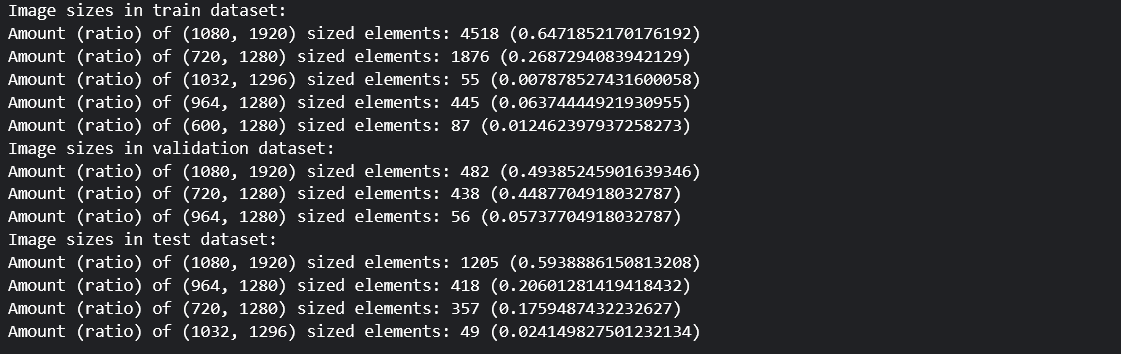

In [24]:
# # Shuffling is ensured by the sampler
# # Train dataloader
# train_dataset_ii = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
#                                 splits = ['train'], hierarchy="high")
# train_batch_sampler_ii = SameShapeBatchSampler(train_dataset_ii, BATCH_SIZE,
#                                             shuffle=True,
#                                             drop_last=True)
# train_loader_ii = DataLoader(
#     train_dataset_ii, batch_sampler=train_batch_sampler_ii, num_workers=4
# )

# # Validation dataloader
# val_dataset_ii = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
#                                 splits = ['val'], hierarchy="high")
# val_batch_sampler_ii = SameShapeBatchSampler(val_dataset_ii, BATCH_SIZE,
#                                           shuffle=False,
#                                           drop_last=False)
# val_loader_ii = DataLoader(
#     val_dataset_ii, batch_sampler=val_batch_sampler_ii, num_workers=4
# )

# # Test dataloader
# test_dataset_ii = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
#                                 splits = ['test'], hierarchy="high")
# test_batch_sampler_ii = SameShapeBatchSampler(test_dataset_ii, BATCH_SIZE,
#                                             shuffle=False,
#                                             drop_last=False)
# test_loader_ii = DataLoader(
#     test_dataset_ii, batch_sampler=test_batch_sampler_ii, num_workers=4
# )

## Image sizes in the part II

In [25]:
# print("Image sizes in train dataset: ")
# train_dataset_ii.image_shapes_quantity(print_flag=True)
# print("Image sizes in validation dataset: ")
# val_dataset_ii.image_shapes_quantity(print_flag=True)
# print("Image sizes in test dataset: ")
# test_dataset_ii.image_shapes_quantity(print_flag=True)

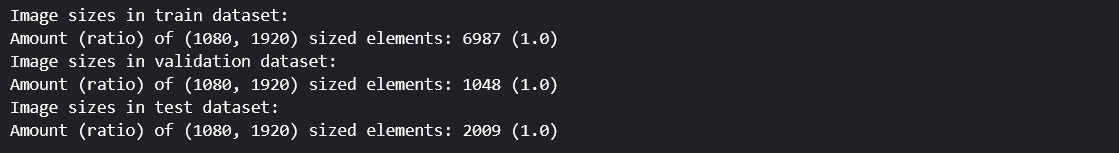

## Full dataset

In [26]:
# # Shuffling is ensured by the sampler
# # Train dataloader
# train_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I','II'],
#                                  splits = ['train'], hierarchy="high")
# train_batch_sampler_full = SameShapeBatchSampler(train_dataset_full, BATCH_SIZE,
#                                             shuffle=True,
#                                             drop_last=True)
# train_loader_full = DataLoader(
#     train_dataset_full, batch_sampler=train_batch_sampler_full, num_workers=4
# )

# # Validation dataloader
# val_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I','II'],
#                                splits = ['val'], hierarchy="high")
# val_batch_sampler_full = SameShapeBatchSampler(val_dataset_full, BATCH_SIZE,
#                                           shuffle=False,
#                                           drop_last=False)
# val_loader_full = DataLoader(
#     val_dataset_full, batch_sampler=val_batch_sampler_full, num_workers=4
# )

# # Test dataloader
# test_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['I','II'],
#                                 splits = ['test'], hierarchy="high")
# test_batch_sampler_full = SameShapeBatchSampler(test_dataset_full, BATCH_SIZE,
#                                             shuffle=False,
#                                             drop_last=False)
# test_loader_full = DataLoader(
#     test_dataset_full, batch_sampler=test_batch_sampler_full, num_workers=4
# )

In [27]:
labeled_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['train'], hierarchy="high")
val_dataset = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['val'], hierarchy="high")
# unlabeled_part_i = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'], splits=['test'], hierarchy="high")
train_lab_dataset, train_unlab_dataset, _, test_dataset = random_split(labeled_full, [0.053242, 0.372549, 0.355947, 0.218262]) # 0.2126, 0.5979, 0.1137, 0.0758
# train_unlab_dataset = ConcatDataset([unlabeled_part_i, unlabeled_part_ii]) # 0.0005, 0.999, 0.00025, 0.00025

In [28]:
# Labeled training dataloader
# Supervised training
train_lab_batch_sampler_st = SameShapeBatchSampler(train_lab_dataset, BATCH_SIZE_ST,
                                            shuffle=True,
                                            drop_last=True)
train_lab_loader_st = DataLoader(
    train_lab_dataset, batch_sampler=train_lab_batch_sampler_st, num_workers=4
)
# Semi-supervised training
train_lab_batch_sampler_sst = SameShapeBatchSampler(train_lab_dataset, BATCH_SIZE_SST,
                                            shuffle=True,
                                            drop_last=True)
train_lab_loader_sst = DataLoader(
    train_lab_dataset, batch_sampler=train_lab_batch_sampler_sst, num_workers=4
)

# Unlabeled training dataloader
train_unlab_batch_sampler = SameShapeBatchSampler(train_unlab_dataset, UNLAB_MULT * BATCH_SIZE_SST,
                                            shuffle=True,
                                            drop_last=True)
train_unlab_loader = DataLoader(
    train_unlab_dataset, batch_sampler=train_unlab_batch_sampler, num_workers=4
)

# Validation dataloader
val_batch_sampler = SameShapeBatchSampler(val_dataset, BATCH_SIZE_ST,
                                          shuffle=False,
                                          drop_last=False)
val_loader = DataLoader(
    val_dataset, batch_sampler=val_batch_sampler, num_workers=4
)

# Test dataloader
test_batch_sampler = SameShapeBatchSampler(test_dataset, BATCH_SIZE_ST,
                                            shuffle=False,
                                            drop_last=False)
test_loader = DataLoader(
    test_dataset, batch_sampler=test_batch_sampler, num_workers=4
)

In [29]:
total_samples = len(train_lab_dataset) + len(train_unlab_dataset) + len(val_dataset) + len(test_dataset)
print(f"Quantity of samples in the current split:")
print(f"   Train labeled: {len(train_lab_dataset)} (ratio: {len(train_lab_dataset)/total_samples})")
print(f"   Train unlabeled: {len(train_unlab_dataset)} (ratio: {len(train_unlab_dataset)/total_samples})")
print(f"   Validation: {len(val_dataset)} (ratio: {len(val_dataset)/total_samples})")
print(f"   Test: {len(test_dataset)} (ratio: {len(test_dataset)/total_samples})")

Quantity of samples in the current split:
   Train labeled: 373 (ratio: 0.06723143475126171)
   Train unlabeled: 2603 (ratio: 0.4691780821917808)
   Validation: 1048 (ratio: 0.18889689978370583)
   Test: 1524 (ratio: 0.2746935832732516)


## Additional info calculation

In [30]:
# temp_batch_size = 128
# # Shuffling is ensured by the sampler
# train_dataset_full = IDD_Dataset("/kaggle/input/indian-driving-dataset", parts = ['II'],
#                                  splits = ['train'], hierarchy="high")
# train_full_batch_sampler_calc = SameShapeBatchSampler(train_dataset_full, temp_batch_size,
#                                             shuffle=True,
#                                             drop_last=False)
# train_full_loader_calc = DataLoader(
#     train_dataset_full, batch_sampler=train_full_batch_sampler_calc, num_workers=4
# )

# to_tensor_pipe = transformsv2.Compose([
#     transformsv2.ToImage(),
#     transformsv2.ToDtype(torch.float32, scale=True)
# ])
# total_len = len(train_full_loader_calc)

### Mean/std calculation

In [31]:
# train_loader_full = DataLoader(
#     train_dataset_full, batch_size=temp_batch_size,
#     sampler=SameShapeBatchSampler(train_dataset_full, temp_batch_size, g_train),
#     drop_last=False, num_workers=4, worker_init_fn=seed_worker, generator=g_train
#     )
# len(train_loader_full)

In [32]:
# # Initialize variables to store sum and sum of squares
# mean_arr = np.zeros((total_len,3))
# std_arr = np.zeros((total_len,3))

# # Iterate over the dataset
# for batch_num, data in tqdm(enumerate(train_full_loader_calc), total=total_len):
#     images, _ = data  # We only need the images, not the masks
#     images = to_tensor_pipe(images).numpy()
#     batch_mean = np.mean(images, axis=(0,2,3))
#     batch_std1 = np.std(images, axis=(0,2,3), ddof=1)
    
#     mean_arr[batch_num, :] = batch_mean
#     std_arr[batch_num, :] = batch_std1

# DATA_MEAN = mean_arr.mean(axis=0)
# DATA_STD = std_arr.mean(axis=0)
# np.save("channel_mean.npy", DATA_MEAN)
# np.save("channel_std.npy", DATA_STD)

### Class weights calculation

In [33]:
# train_loader_full = DataLoader(
#     train_dataset_full, batch_size=temp_batch_size,
#     sampler=SameShapeBatchSampler(train_dataset_full, temp_batch_size, g_train),
#     drop_last=False, num_workers=4, worker_init_fn=seed_worker, generator=g_train
#     )
# len(train_loader_full)

In [34]:
# # Convert to numpy array
# total_class_ratios = np.zeros(HIGH_NUM_CLASSES)

# # Iterate over the dataset
# for batch_num, data in tqdm(enumerate(train_full_loader_calc), total=total_len):
#     _, masks = data  # We only need the masks, not the images
#     masks_np = masks.detach().cpu().numpy()
#     class_counts = [(masks_np == cls).sum(axis=(1, 2)) for cls in range(HIGH_NUM_CLASSES)]
#     class_ratios = np.array(class_counts) / (masks_np != HIGH_NUM_CLASSES).sum(axis=(1, 2)) # unlabeled pixels not taken into account
#     # Calculate the mean ratio for each class across all masks
#     mean_ratios = class_ratios.mean(axis=1)
#     total_class_ratios += mean_ratios
    
# class_weights_ii = total_class_ratios / total_len

In [35]:
# np.save("class_ratio_dataset_ii.npy", class_weights_ii)

In [36]:
# np.save("class_weights_dataset_ii.npy",\
#         np.round((1/class_weights_ii) / (np.min(1/class_weights_ii)), 5))

### File reading time calculation

In [37]:
# from torchvision.io.image import decode_jpeg, read_file
# from torchvision.io import read_image
# start = time.time()
# img = PIL.Image.open("/kaggle/input/indian-driving-dataset/idd_seg_part_II_leftImg8bit/train/201/frame0029_leftImg8bit.jpg")
# tensor = read_image("/kaggle/input/indian-driving-dataset/idd_seg_part_I_leftImg8bit/train/0/005506_leftImg8bit.png")
# data = read_file("/kaggle/input/indian-driving-dataset/idd_seg_part_II_leftImg8bit/train/201/frame0029_leftImg8bit.jpg")
# tensor = decode_jpeg(data, device="cpu")
# img = np.array(img)
# img = torchvision.transforms.functional.pil_to_tensor(img)
# array = np.load("/kaggle/input/indian-driving-dataset/idd_seg_part_I_gtFine/train/0/005506_gtFine_polygons.npz")['masks']
# end = time.time()
# end - start

# Augmentation visualisations

In [ ]:
model_b1 = model_b1.to(DEVICE)
test_img, test_real_mask = train_lab_dataset[0]
apply_model_and_show_results(
    model = model_b1,
    image = test_img,
    new_height = NEW_HEIGHT,
    new_width = NEW_WIDTH,
    real_mask = test_real_mask
)

In [39]:
apply_model_and_show_results(
    model = model_b1,
    image = test_img,
    new_height = NEW_HEIGHT,
    new_width = NEW_WIDTH,
    real_mask = test_real_mask,
    transform = strong_transform_st
)

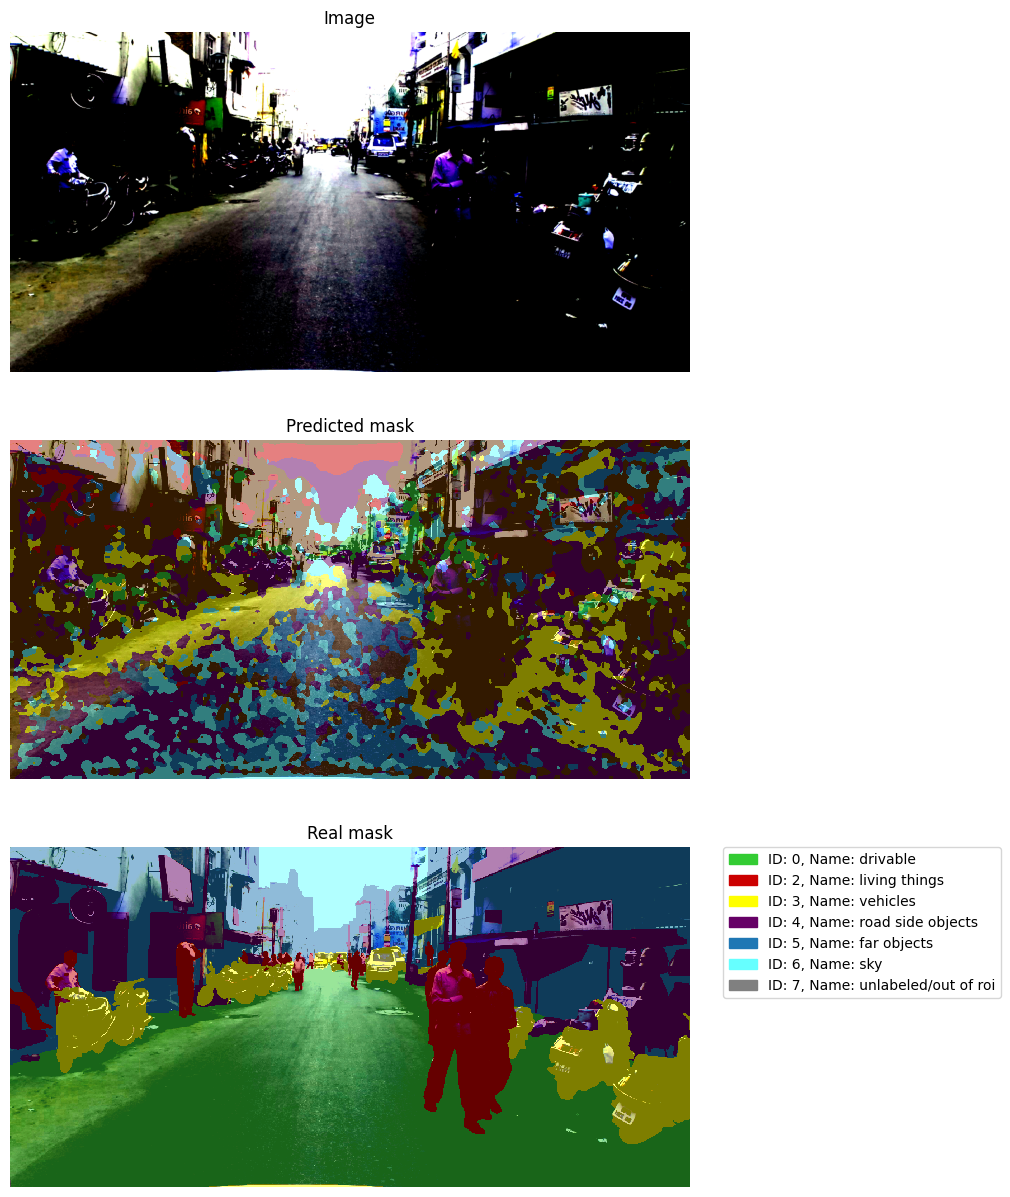

In [ ]:
apply_model_and_show_results(
    model = model_b1,
    image = test_img,
    new_height = NEW_HEIGHT,
    new_width = NEW_WIDTH,
    real_mask = test_real_mask,
    transform = transformsv2.Compose([weak_transform_i, weak_transform_ii])
)

In [ ]:
apply_model_and_show_results(
    model = model_b1,
    image = test_img,
    new_height = 640,
    new_width = 1280,
    real_mask = test_real_mask,
    transform = inference_transform
)

# Lightning Modules
# Supervised training

In [42]:
# define the LightningModule
class LitSegSupervised(L.LightningModule):
    def __init__(
        self,
        seg_model,
        train_loader,
        val_dataset,
        test_dataset,
        level_mapping,
        strong_transform,
        inference_transform,
        output_epoch=1,
        num_warmup_epochs=2,
        row_num=5,
        criterion = nn.CrossEntropyLoss,
        cmap=HIGH_CMAP,
        norm=HIGH_NORM,
        std_img=STD_TRN,
        mean_img=MEAN_TRN,
        weights=CLASS_WEIGHTS
    ):
        super().__init__()
        self.seg_model = seg_model
        self.num_classes = seg_model.head.output_ops[0].op_list[1].conv.out_channels
        self.ignored_index = len(level_mapping) - 1
        
        if weights is not None:
            weights = weights.float()
        
        self.criterion = criterion(weight=weights, ignore_index=self.ignored_index)
        self.row_num = row_num
        self.train_loader_len = len(train_loader)
        self.output_epoch = output_epoch
        self.num_warmup_epochs = num_warmup_epochs
        self.strong_aug = strong_transform
        self.inference_transform = inference_transform
        self.std_img = std_img
        self.mean_img = mean_img

#         self.mean_iou = CustomMeanIoU(num_classes=self.num_classes+1, include_background=False)
#         self.dice = CustomGeneralizedDiceScore(num_classes=self.num_classes+1, include_background=False)

        # 0 - train, 1 - validation, 2 - test
        self.mean_iou = nn.ModuleList([
            MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)\
            for _ in range(3)
        ])
        self.dice = nn.ModuleList([
            Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])
        self.precision = nn.ModuleList([
            MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])
        self.recall = nn.ModuleList([
            MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])
        self.accuracy = nn.ModuleList([
            MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(3)
        ])

        
        def get_control_data(dataset, num_items, img_shape=(3, 1080, 1920)):
            image_list, mask_list = [], []
            count = 0
            # Iterate over the dataset
            for image, mask in dataset:
                # Stop after num_items iterations
                if count == num_items:
                    break
                elif image.shape != img_shape:
                    continue
                # Add the tensors to the lists
                image_list.append(image)
                mask_list.append(mask)
                count += 1

            # Convert the lists of tensors to a single tensor
            images = torch.stack(image_list)
            masks = Mask(torch.stack(mask_list))
            return images, masks
        
        self.val_control_images, self.val_control_masks = get_control_data(val_dataset, row_num)
        self.test_control_images, self.test_control_masks = get_control_data(test_dataset, row_num)

        self.cmap = cmap
        self.norm = norm


    def forward(self, x):
        return self.seg_model(x)


    def training_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.strong_aug(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[0](pred_labels, y)
        self.precision[0](pred_labels, y)
        self.recall[0](pred_labels, y)
        self.accuracy[0](pred_labels, y)
        self.dice[0](pred_labels, y)

        self.log_dict({
            'train_loss': loss, 
            'train_mIoU': self.mean_iou[0],
            'train_precision': self.precision[0],
            'train_recall': self.recall[0],
            'train_accuracy': self.accuracy[0],
            'train_dice_score': self.dice[0],
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True)

        return loss


    def validation_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[1](pred_labels, y)
        self.precision[1](pred_labels, y)
        self.recall[1](pred_labels, y)
        self.accuracy[1](pred_labels, y)
        self.dice[1](pred_labels, y)

        self.log_dict({
            'val_loss': loss, 
            'val_mIoU': self.mean_iou[1],
            'val_precision': self.precision[1],
            'val_recall': self.recall[1],
            'val_accuracy': self.accuracy[1],
            'val_dice_score': self.dice[1],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)


    def on_validation_epoch_end(self):
        if self.current_epoch % self.output_epoch == 0:
            x, y = self.inference_transform(
                self.val_control_images.to(self.device),
                self.val_control_masks.to(self.device)
            )
            # Get the model predictions for the control images
            y = y.long()
            logits = self(x)
            if logits.shape[2:] != y.shape[1:]:
                logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

            # Convert the tensors to numpy arrays
            control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
            control_masks_np = y.detach().cpu().numpy()

            # Create a figure with self.row_num rows and 3 columns
            fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

            # Loop over the images, predicted masks, and actual masks
            for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
                # Display the image in the first column
                axs[i, 0].imshow(img, interpolation='none')
                axs[i, 0].axis('off')

                # Overlay the predicted mask on the image and display it in the second column
                axs[i, 1].imshow(img, cmap='gray', interpolation='none')
                axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 1].axis('off')

                # Overlay the actual mask on the image and display it in the third column
                axs[i, 2].imshow(img, cmap='gray', interpolation='none')
                axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 2].axis('off')

            # Display the figure
            plt.show()
        

    def test_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[2](pred_labels, y)
        self.precision[2](pred_labels, y)
        self.recall[2](pred_labels, y)
        self.accuracy[2](pred_labels, y)
        self.dice[2](pred_labels, y)
        
        self.log_dict({
            'test_loss': loss, 
            'test_mIoU': self.mean_iou[2],
            'test_precision': self.precision[2],
            'test_recall': self.recall[2],
            'test_accuracy': self.accuracy[2],
            'test_dice_score': self.dice[2],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)


    def on_test_epoch_end(self):
        x, y = self.inference_transform(
            self.test_control_images.to(self.device),
            self.test_control_masks.to(self.device)
        )
        # Get the model predictions for the control images
        y = y.long()
        logits = self(x)
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

        # Convert the tensors to numpy arrays
        control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
        control_masks_np = y.detach().cpu().numpy()

        # Create a figure with self.row_num rows and 3 columns
        fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

        # Loop over the images, predicted masks, and actual masks
        for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
            # Display the image in the first column
            axs[i, 0].imshow(img, interpolation='none')
            axs[i, 0].axis('off')

            # Overlay the predicted mask on the image and display it in the second column
            axs[i, 1].imshow(img, cmap='gray', interpolation='none')
            axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 1].axis('off')

            # Overlay the actual mask on the image and display it in the third column
            axs[i, 2].imshow(img, cmap='gray', interpolation='none')
            axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 2].axis('off')

        # Display the figure
        plt.show()


    def configure_optimizers(self):
        params = list(self.seg_model.named_parameters())

        def is_backbone(n): return 'backbone' in n

        grouped_parameters = [
            {"params": [p for n, p in params if is_backbone(n)], 'lr': 1e-4}, # 7e-4
            {"params": [p for n, p in params if not is_backbone(n)], 'lr': 1e-3}, # 7e-3
        ]

        optimizer = torch.optim.AdamW(
            grouped_parameters, weight_decay=1e-4
        )
        
        num_warmup_steps = self.num_warmup_epochs * self.train_loader_len
        num_training_steps = self.trainer.max_epochs * self.train_loader_len
        scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps, num_training_steps)

        return {"optimizer": optimizer, "lr_scheduler": scheduler}

## Training

In [43]:
# !dir /kaggle/working/checkpoints

In [44]:
# lit_model_b1 = LitSegSupervised.load_from_checkpoint(
#     "/kaggle/input/efficientvit-checkpoint/EViT_sup_pretr_80ep_warmup8_trcrop_eq_tstcrop_608X1216_data2_0125labdata_prt2-epoch72-val_mIoU0.69292.ckpt",
#     seg_model=model_b1,
#     train_loader=train_lab_loader_st,
#     val_dataset=val_dataset,
#     test_dataset=test_dataset,
#     level_mapping=HIGH_LEVEL_MAPPING,
#     strong_transform=strong_transform_st,
#     inference_transform=inference_transform,
#     output_epoch=10,
#     num_warmup_epochs=8,
#     weights=None)

In [45]:
# torch.save(lit_model_b1.seg_model, "EfficientVit_supv_608_1216_80_ep_samecrop_data2_lab0125.pth")

In [46]:
# lit_model_b1 = LitSegSupervised(model_b1, train_lab_loader_st, val_dataset, test_dataset,
#     HIGH_LEVEL_MAPPING, strong_transform_st, inference_transform, output_epoch=8, num_warmup_epochs=8,
#     weights=None)

# # Initialize a model checkpoint callback
# checkpoint_callback = ModelCheckpoint(
#     monitor='val_mIoU',
#     dirpath='/kaggle/working/checkpoints',
#     filename='EViT_sup_pretr_80ep_warmup8_trcrop_eq_tstcrop_608X1216_data2_0125labdata_prt2-{epoch:02d}-{val_mIoU:.5f}',
#     save_last=True,
#     save_top_k=1,
#     mode='max',
# )

# # Define the early stopping callback when mIoU has stopped improving
# early_stop_callback = EarlyStopping(
#     monitor="val_mIoU",
#     min_delta=0.00,
#     patience=10,
#     verbose=False,
#     mode="max"
# )

# trainer = L.Trainer(
#     max_epochs=80,
#     enable_checkpointing=True,
#     callbacks=[checkpoint_callback, early_stop_callback],
#     logger=TensorBoardLogger('lightning_logs', name='EViT_sup_pretr_80ep_warmup8_trcrop_eq_tstcrop_608X1216_data2_0125labdata_prt2'),
# #     limit_train_batches=2,
# #     limit_val_batches=2
# )
# trainer.fit(lit_model_b1, train_lab_loader_st, val_loader, ckpt_path="/kaggle/input/efficientvit-checkpoint/EViT_sup_pretr_80ep_warmup8_trcrop_eq_tstcrop_608X1216_data2_0125labdata-epoch49-val_mIoU0.67488.ckpt")

In [47]:
# !zip -r /kaggle/working/lightning_logs.zip /kaggle/working/efficientvit/lightning_logs

In [48]:
# !zip -r /kaggle/working/checkpoints.zip /kaggle/working/checkpoints

In [49]:
# trainer.test(lit_model_b1, test_loader, ckpt_path="/kaggle/working/checkpoints/EViT_sup_pretr_80ep_warmup8_trcrop_eq_tstcrop_608X1216_data2_0125labdata_prt2-epoch=72-val_mIoU=0.69292.ckpt")

In [50]:
# torch.save(lit_model_b1.seg_model, "EfficientVit_supv_416_832_80_ep_samecrop_data2_mIoU_69_705.pth")

# Semi-supervised finetune

In [51]:
# define the LightningModule
class LitSegSemiSupervised(LitSegSupervised):
    def __init__(
        self,
        seg_model,
        train_lab_loader,
        val_dataset,
        test_dataset,
        level_mapping,
        strong_transform_st,
        pre_strong_transform_sst,
        post_strong_transform_sst,
        weak_transform_i,
        weak_transform_ii,
        inference_transform,
        confidence_threshold=0.95,
        mu=5,
        output_epoch=1,
        num_warmup_epochs=2,
        row_num=5,
        criterion = nn.CrossEntropyLoss,
        cmap=HIGH_CMAP,
        norm=HIGH_NORM,
        std_img=STD_TRN,
        mean_img=MEAN_TRN,
        decay_val=DECAY_VAL,
        weights=CLASS_WEIGHTS,
        weighting="ordinary"
    ):
        super().__init__(
            seg_model,
            train_lab_loader,
            val_dataset,
            test_dataset,
            level_mapping,
            strong_transform=strong_transform_st,
            inference_transform=inference_transform,
            output_epoch=output_epoch,
            num_warmup_epochs=num_warmup_epochs,
            row_num=row_num,
            criterion=criterion,
            cmap=cmap,
            norm=norm,
            std_img=std_img,
            mean_img=mean_img,
            weights=weights
        )
        self.seg_model = self.seg_model.to(DEVICE)

#         self.teacher_even = ExponentialMovingAverage(self.seg_model.parameters(), decay=decay_val)
#         self.teacher_odd = ExponentialMovingAverage(self.seg_model.parameters(), decay=decay_val)
        self.teacher_even = deepcopy(self.seg_model).to(DEVICE)
        self.teacher_odd = deepcopy(self.seg_model).to(DEVICE)
        
        if weighting!="ordinary" and weighting!="laplace":
            raise Exception(f"Error: unsupported weighting: {weighting}")
        else:
            self.weighting = weighting
        
        self.pre_strong_aug_sst = pre_strong_transform_sst
        self.post_strong_aug_sst = post_strong_transform_sst
        self.weak_aug_i = weak_transform_i
        self.weak_aug_ii = weak_transform_ii
        self.thr = confidence_threshold
        self.mu = mu
        self.alpha_max = decay_val
        self.current_best_model_idx = None
        
        if weights is not None:
            weights = weights.float()
        
        self.criterion_ul = criterion(reduction='none', weight=weights, ignore_index=self.ignored_index)
#         self.mean_iou_ul = CustomMeanIoU(num_classes=self.num_classes+1, include_background=False)
#         self.dice_ul = CustomGeneralizedDiceScore(num_classes=self.num_classes+1, include_background=False)
        self.mean_iou_ul = MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.dice_ul = Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.precision_ul = MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.recall_ul = MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.accuracy_ul = MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)

        # 0 - teacher_even valid, 1 - teacher_odd valid, 2 - teacher_even test, 3 - teacher_odd test
        self.mean_iou_teach = nn.ModuleList([
            MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)\
            for _ in range(4)
        ])
        self.dice_teach = nn.ModuleList([
            Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])
        self.precision_teach = nn.ModuleList([
            MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])
        self.recall_teach = nn.ModuleList([
            MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])
        self.accuracy_teach = nn.ModuleList([
            MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(4)
        ])

    def on_train_epoch_start(self):
#         self.confidence_statistics = []
#         self.time_stats = [[],[],[],[],[],[],[],[],[]]
        if self.current_epoch % 2 == 0:
            self.current_teacher = self.teacher_even
            self.current_main_aug = self.cut_mix
        else:
            self.current_teacher = self.teacher_odd
            self.current_main_aug = self.class_mix


    def training_step(self, batch, batch_idx):
#         start = time.time()
        lab_batch, unlab_batch = batch['lab'], batch['unlab']

        # Supervised part
        x_lab, y_lab = lab_batch
        lab_batch_size = x_lab.shape[0]
        with torch.no_grad():
            y_lab = Mask(y_lab)
            x_lab, y_lab = self.strong_aug(x_lab, y_lab)
            y_lab = y_lab.long()
        logits_lab = self(x_lab)
        # Upsample logits if necessary
        if logits_lab.shape[2:] != y_lab.shape[1:]:
            logits_lab = F.interpolate(logits_lab, size=y_lab.shape[1:], mode='bicubic', align_corners=False)
        labeled_loss = self.criterion(logits_lab, y_lab)
        pred_labels_lab = logits_lab.argmax(dim=1)
#         end = time.time()
#         self.time_stats[0].append(end-start) # 0 - supervised part time
        
#         del x_lab, logits_lab
#         torch.cuda.empty_cache()
    
        # Unsupervised part
#         start = time.time()
        x_unlab, _ = unlab_batch
#         print("1")
#         print(torch.isnan(x_unlab).any())
        unlab_batch_size = x_unlab.shape[0]
        with torch.no_grad():
            x_unlab = self.weak_aug_i(x_unlab)
#             print("2")
#             print(torch.isnan(x_unlab).any())
            x_weak = self.weak_aug_ii(x_unlab)
#             print("3")
#             print(torch.isnan(x_weak).any())
#             end = time.time()
#             self.time_stats[1].append(end-start) # 1 - weak augmentation
#             start = time.time()

            # Old EMA teacher pipeline
#             with self.current_teacher.average_parameters():
#                 self.seg_model.eval()
#                 teacher_logits = self(x_weak)
#                 self.seg_model.train()

            self.current_teacher.eval()
            teacher_logits = self.current_teacher(x_weak)

#             end = time.time()
#             self.time_stats[2].append(end-start) # 2 - forwarding through teacher model
#             start = time.time()
            class_num = teacher_logits.shape[1]
#             print("4")
#             print(torch.isnan(teacher_logits).any())
            if teacher_logits.shape[2:] != x_weak.shape[2:]:
                teacher_logits = F.interpolate(teacher_logits, size=x_weak.shape[2:], mode='bicubic', align_corners=False)
#             print("5")
#             print(torch.isnan(teacher_logits).any())
#             print(teacher_logits.shape)

            y_unlab = torch.softmax(teacher_logits, dim=1) # predicted teacher probabilities
            # currently testing option of using logits instead

#             print("6")
#             print(torch.isnan(y_unlab).any())
#             print(y_unlab.shape)
#             print(torch.max(y_unlab, dim=1).values)
#             print(torch.max(y_unlab, dim=1).values.shape)
            pixel_conf, pseudo_labels = torch.max(y_unlab, dim=1)
#             end = time.time()
#             self.time_stats[3].append(end-start) # 3 - interpolation and middle calculations
#             start = time.time()
            x_unlab = CENTER_CROP_AUG(x_unlab)
            x_unlab, pseudo_labels, pixel_conf = self.pre_strong_aug_sst(x_unlab, Mask(pseudo_labels), Mask(pixel_conf)) # y_unlab is N x C x H x W
#             end = time.time()
#             self.time_stats[4].append(end-start) # 4 - pre strong aug
#             start = time.time()
            x_unlab_aug, y_unlab_aug, pixel_conf = self.current_main_aug(x_unlab, pseudo_labels, pixel_conf, unlab_batch_size)
#             end = time.time()
#             self.time_stats[5].append(end-start) # 5 - main aug
#             start = time.time()
            x_unlab_aug, y_unlab_aug, pixel_conf = self.post_strong_aug_sst(x_unlab_aug, Mask(y_unlab_aug), Mask(pixel_conf))
#             end = time.time()
#             self.time_stats[6].append(end-start) # 6 - post strong aug
#             start = time.time()
#             print(torch.isnan(x_unlab_aug).any())
#             print(torch.isnan(y_unlab_aug).any())

#             thr_samples = sample_weights >= self.thr
#             if thr_samples.any().item():
#                 x_unlab_aug, y_unlab_aug = x_unlab_aug[thr_samples], y_unlab_aug[thr_samples]
#             else:
#                 x_unlab_aug, y_unlab_aug = x_unlab_aug[torch.argmax(sample_weights)].unsqueeze(0),\
#                 y_unlab_aug[torch.argmax(sample_weights)].unsqueeze(0)
#             thr_passed_quant = torch.sum(thr_samples).item()

#             print("8")
#             print(torch.isnan(x_unlab_aug).any())
#             print(torch.isnan(y_unlab_aug).any())
#             print(torch.isnan(roi_mask).any())
#             print(y_unlab_aug)

#             y_unlab_aug = y_unlab_aug / y_unlab_aug.sum(dim=1, keepdim=True)
#             y_unlab_aug = torch.softmax(y_unlab_aug, dim=1)

#             print(torch.isnan(y_unlab_aug).any())

            #!!!! added
            if self.weighting == "ordinary":
                pixel_conf = (torch.sum(
                    torch.ge(pixel_conf, self.thr).long(),
                    dim=(1,2)
                ) / torch.numel(y_unlab_aug[0])).unsqueeze(1)
                mean_ratio_of_confid_pix = torch.mean(pixel_conf).item()
            else:
                pixel_conf, conf_thresh = LitSegSemiSupervised.calculate_pixel_weights(pixel_conf)
#         try:
        logits_unlab = self(x_unlab_aug)
#         except RuntimeError as e:
#             print(f"Caught runtime error {e} for input of shape {x_unlab_aug.shape}")
#         print("9")
#         print(torch.isnan(logits_unlab).any())
        # Upsample logits if necessary
        if logits_unlab.shape[2:] != y_unlab_aug.shape[1:]:
            logits_unlab = F.interpolate(logits_unlab, size=y_unlab_aug.shape[1:], mode='bicubic', align_corners=False)
#         print("10")
#         print(torch.isnan(logits_unlab).any())
#         out_of_roi_mask = roi_mask == 0 # batch_size x height x width
        unlabeled_loss = self.criterion_ul(
            logits_unlab,
            y_unlab_aug # pseudo-labels
        ) #changed !!!!!!!!!!

#         unlabeled_loss = unlabeled_loss * pixel_conf
#         print("10")
#         print(torch.isnan(unlabeled_loss).any())
#         print(unlabeled_loss)
#         print(logits_unlab)
#         print(y_unlab_aug)
#         print(augment_determiners)
#         sample_weights = torch.from_numpy(sample_weights[:,np.newaxis]).to(self.device)

        #!!!!!!!!!!
        unlabeled_loss = torch.mean(unlabeled_loss * pixel_conf) # unlabeled_loss = torch.mean(unlabeled_loss) 
        
#         print(torch.isnan(unlabeled_loss).any())
        pred_labels_unlab = logits_unlab.argmax(dim=1)
#         labels_unlab[out_of_roi_mask] = self.ignored_index
#         y_unlab_discrete = y_unlab_aug.argmax(dim=1)
#         y_unlab_discrete[out_of_roi_mask] = self.ignored_index
        
        total_loss = labeled_loss + self.get_mu(batch_idx) * unlabeled_loss
#         end = time.time()
#         self.time_stats[7].append(end-start) # 7 - upsampling pseudo labes, calculating unlab logits
#         start = time.time()
#         end_time = time.time()
#         print(f"Part III time: {end_time-start_time}")
#         print(y_lab.shape)
#         print(labels_lab.shape)
        
#         print(np.unique(y_lab))
#         print(np.unique(labels_lab))
#         print(f"Labeled loss: {labeled_loss}")
#         print(f"Unlabeled loss: {unlabeled_loss}")
        self.mean_iou[0](pred_labels_lab, y_lab)
        self.precision[0](pred_labels_lab, y_lab)
        self.recall[0](pred_labels_lab, y_lab)
        self.accuracy[0](pred_labels_lab, y_lab)
        self.dice[0](pred_labels_lab, y_lab)
        
        self.mean_iou_ul(pred_labels_unlab, y_unlab_aug)
        self.precision_ul(pred_labels_unlab, y_unlab_aug)
        self.recall_ul(pred_labels_unlab, y_unlab_aug)
        self.accuracy_ul(pred_labels_unlab, y_unlab_aug)
        self.dice_ul(pred_labels_unlab, y_unlab_aug)

        # Logging several times, since labeled and unlabeled batch sizes are different
        self.log_dict({
            'train_total_loss': total_loss
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True)
        self.log_dict({
            'train_labeled_loss': labeled_loss,
            'train_mIoU_lab': self.mean_iou[0],
            'train_precision_lab': self.precision[0],
            'train_recall_lab': self.recall[0],
            'train_accuracy_lab': self.accuracy[0],
            'train_dice_score_lab': self.dice[0]
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True, batch_size=lab_batch_size)
        self.log_dict({
            'train_unlabeled_loss': unlabeled_loss,
            'quant_of_img_passed_thr' if self.weighting == "ordinary" else "20th_percentile":\
                mean_ratio_of_confid_pix if self.weighting == "ordinary" else conf_thresh,
            'train_mIoU_unlab': self.mean_iou_ul,
            'train_precision_unlab': self.precision_ul,
            'train_recall_unlab': self.recall_ul,
            'train_accuracy_unlab': self.accuracy_ul,
            'train_dice_score_unlab': self.dice_ul                                                #!!!!!!!!!!
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True, batch_size=unlab_batch_size) # replaced unlab_batch_size
#         end = time.time()
#         self.time_stats[8].append(end-start) # 8 - metrics and logging
#         np.save("time_stats.npy", np.array(self.time_stats))
#         self.confidence_statistics.append(pixel_conf.detach().cpu().numpy())
#         with open('conf_stat.pkl', 'wb') as file:
#             pickle.dump(self.confidence_statistics, file)
#         entire_stop = time.time()
#         print(f"Entire train time: {entire_stop-entire_start}")

#         self.current_teacher.decay = self.get_decay(batch_idx)
        self.current_batch_idx = batch_idx
        return total_loss


#     def on_train_epoch_end(self):
#         self.confidence_statistics = np.array(self.confidence_statistics)
#         np.save("conf_stat.npy", self.confidence_statistics)


    def validation_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits_student = self(x)
        # Upsample logits if necessary
        if logits_student.shape[2:] != y.shape[1:]:
            logits_student = F.interpolate(logits_student, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits_student, y)
        pred_labels = logits_student.argmax(dim=1)

        self.mean_iou[1](pred_labels, y)
        self.precision[1](pred_labels, y)
        self.recall[1](pred_labels, y)
        self.accuracy[1](pred_labels, y)
        self.dice[1](pred_labels, y)

        self.log_dict({
            'val_loss': loss, 
            'val_mIoU': self.mean_iou[1],
            'val_precision': self.precision[1],
            'val_recall': self.recall[1],
            'val_accuracy': self.accuracy[1],
            'val_dice_score': self.dice[1],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

        del logits_student, loss, pred_labels
        torch.cuda.empty_cache()

        for idx, teacher, name in zip(range(2),
                                      (self.teacher_even, self.teacher_odd),
                                      ("teach_even", "teach_odd")):
            
            # Old EMA teacher pipeline
#             with teacher.average_parameters():
#                 teacher_logits = self(x)
            with torch.no_grad():
                teacher.eval()
                teacher_logits = teacher(x)

            # Upsample logits if necessary
            if teacher_logits.shape[2:] != y.shape[1:]:
                teacher_logits = F.interpolate(teacher_logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            loss = self.criterion(teacher_logits, y)
            pred_labels = teacher_logits.argmax(dim=1)

            self.mean_iou_teach[idx](pred_labels, y)
            self.precision_teach[idx](pred_labels, y)
            self.recall_teach[idx](pred_labels, y)
            self.accuracy_teach[idx](pred_labels, y)
            self.dice_teach[idx](pred_labels, y)

            self.log_dict({
                f'val_loss_{name}': loss, 
                f'val_mIoU_{name}': self.mean_iou_teach[idx],
                f'val_precision_{name}': self.precision_teach[idx],
                f'val_recall_{name}': self.recall_teach[idx],
                f'val_accuracy_{name}': self.accuracy_teach[idx],
                f'val_dice_score_{name}': self.dice_teach[idx],
                }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

            del teacher_logits, loss, pred_labels
            torch.cuda.empty_cache()

   
    def on_validation_epoch_end(self):
        # Compute the maximum mIoU
        mIoU_models_arr = torch.tensor([
            self.mean_iou[1].compute(), # student val mIoU
            self.mean_iou_teach[0].compute(), # teacher_cutmix val mIoU
            self.mean_iou_teach[1].compute() # teacher_classmix val mIoU
        ])
        current_best_model_idx = torch.argmax(mIoU_models_arr)
        current_best_mIoU = mIoU_models_arr[current_best_model_idx]
        # Log the custom metric
        self.log('max_val_mIoU', current_best_mIoU)
        if current_best_model_idx == 0:
            current_best_model = self
        elif current_best_model_idx == 1:
            current_best_model = self.teacher_even
        elif current_best_model_idx == 2:
            current_best_model = self.teacher_odd
        else:
            raise Exception(f"Unknown best model with idx: {current_best_model_idx}")
        
        if self.current_epoch % self.output_epoch == 0:
            x, y = self.inference_transform(
                self.val_control_images.to(self.device),
                self.val_control_masks.to(self.device)
            )
            # Get the model predictions for the control images
            y = y.long()
            logits = current_best_model(x)
            if logits.shape[2:] != y.shape[1:]:
                logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

            # Convert the tensors to numpy arrays
            control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
            control_masks_np = y.detach().cpu().numpy()

            # Create a figure with self.row_num rows and 3 columns
            fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

            # Loop over the images, predicted masks, and actual masks
            for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
                # Display the image in the first column
                axs[i, 0].imshow(img, interpolation='none')
                axs[i, 0].axis('off')

                # Overlay the predicted mask on the image and display it in the second column
                axs[i, 1].imshow(img, cmap='gray', interpolation='none')
                axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 1].axis('off')

                # Overlay the actual mask on the image and display it in the third column
                axs[i, 2].imshow(img, cmap='gray', interpolation='none')
                axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
                axs[i, 2].axis('off')

            # Display the figure
            plt.show()
            
            
    def test_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits = self(x)
        # Upsample logits if necessary
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits, y)
        pred_labels = logits.argmax(dim=1)

        self.mean_iou[2](pred_labels, y)
        self.precision[2](pred_labels, y)
        self.recall[2](pred_labels, y)
        self.accuracy[2](pred_labels, y)
        self.dice[2](pred_labels, y)
        
        self.log_dict({
            'test_loss': loss, 
            'test_mIoU': self.mean_iou[2],
            'test_precision': self.precision[2],
            'test_recall': self.recall[2],
            'test_accuracy': self.accuracy[2],
            'test_dice_score': self.dice[2],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)
        
        del logits, loss, pred_labels
        torch.cuda.empty_cache()
        
        for idx, teacher, name in zip(range(2, 4),
                              (self.teacher_even, self.teacher_odd),
                              ("teach_even", "teach_odd")):

            with torch.no_grad():
                teacher.eval()
                teacher_logits = teacher(x)

            # Upsample logits if necessary
            if teacher_logits.shape[2:] != y.shape[1:]:
                teacher_logits = F.interpolate(teacher_logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            loss = self.criterion(teacher_logits, y)
            pred_labels = teacher_logits.argmax(dim=1)

            self.mean_iou_teach[idx](pred_labels, y)
            self.precision_teach[idx](pred_labels, y)
            self.recall_teach[idx](pred_labels, y)
            self.accuracy_teach[idx](pred_labels, y)
            self.dice_teach[idx](pred_labels, y)

            self.log_dict({
                f'test_loss_{name}': loss, 
                f'test_mIoU_{name}': self.mean_iou_teach[idx],
                f'test_precision_{name}': self.precision_teach[idx],
                f'test_recall_{name}': self.recall_teach[idx],
                f'test_accuracy_{name}': self.accuracy_teach[idx],
                f'test_dice_score_{name}': self.dice_teach[idx],
                }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

            del teacher_logits, loss, pred_labels
            torch.cuda.empty_cache()


    def on_test_epoch_end(self):
        # Compute the maximum mIoU
        mIoU_models_arr = torch.tensor([
            self.mean_iou[2].compute(), # student test mIoU
            self.mean_iou_teach[2].compute(), # teacher_cutmix test mIoU
            self.mean_iou_teach[3].compute() # teacher_classmix test mIoU
        ])
        current_best_model_idx = torch.argmax(mIoU_models_arr)
        current_best_mIoU = mIoU_models_arr[current_best_model_idx]
        # Log the custom metric
        self.log('max_test_mIoU', current_best_mIoU)
        if current_best_model_idx == 0:
            current_best_model = self
        elif current_best_model_idx == 1:
            current_best_model = self.teacher_even
        elif current_best_model_idx == 2:
            current_best_model = self.teacher_odd
        else:
            raise Exception(f"Unknown best model with idx: {current_best_model_idx}")

        x, y = self.inference_transform(
            self.test_control_images.to(self.device),
            self.test_control_masks.to(self.device)
        )
        # Get the model predictions for the control images
        y = y.long()
        logits = current_best_model(x)
        if logits.shape[2:] != y.shape[1:]:
            logits = F.interpolate(logits, size=y.shape[1:], mode='bicubic', align_corners=False)
        preds_np = logits.argmax(dim=1).float().detach().cpu().numpy()

        # Convert the tensors to numpy arrays
        control_images_np = (x.detach().cpu() * self.std_img[:,None,None] + self.mean_img[:,None,None]).permute(0, 2, 3, 1).numpy()
        control_masks_np = y.detach().cpu().numpy()

        # Create a figure with self.row_num rows and 3 columns
        fig, axs = plt.subplots(self.row_num, 3, figsize=(15, 25))

        # Loop over the images, predicted masks, and actual masks
        for i, (img, pred, mask) in enumerate(zip(control_images_np, preds_np, control_masks_np)):
            # Display the image in the first column
            axs[i, 0].imshow(img, interpolation='none')
            axs[i, 0].axis('off')

            # Overlay the predicted mask on the image and display it in the second column
            axs[i, 1].imshow(img, cmap='gray', interpolation='none')
            axs[i, 1].imshow(pred, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 1].axis('off')

            # Overlay the actual mask on the image and display it in the third column
            axs[i, 2].imshow(img, cmap='gray', interpolation='none')
            axs[i, 2].imshow(mask, cmap=self.cmap, norm=self.norm, alpha=0.5, interpolation='none') 
            axs[i, 2].axis('off')

        # Display the figure
        plt.show()


    def on_before_zero_grad(self, *args, **kwargs):
#         self.current_teacher.update(self.seg_model.parameters())
        LitSegSemiSupervised.update_ema_parameters(
            self.current_teacher, self.seg_model, self.get_decay(self.current_batch_idx)
        )


    def configure_optimizers(self):
        params = list(self.seg_model.named_parameters())

        def is_backbone(n): return 'backbone' in n

        grouped_parameters = [
            {"params": [p for n, p in params if is_backbone(n)], 'lr': 5e-4},#5e-4
            {"params": [p for n, p in params if not is_backbone(n)], 'lr': 2e-3},#2e-3
        ]

        optimizer = torch.optim.AdamW(
            grouped_parameters, weight_decay=1e-4
        )
        
        num_warmup_steps = self.num_warmup_epochs * self.train_loader_len
        num_training_steps = self.trainer.max_epochs * self.train_loader_len
        scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps, num_training_steps)

        return {"optimizer": optimizer, "lr_scheduler": scheduler}


    def cut_mix(self, x_unlab, pseudo_labels, pixel_conf, unlab_batch_size, threshold=0.95):
        x_unlab_aug, pseudo_labels_aug = x_unlab.clone(), pseudo_labels.clone()
        shuff_idx = torch.randperm(unlab_batch_size).detach().to(self.device) # permutation indexes
        # Line of the code below won't work correctly together with affine transformations
        mean_conf = torch.mean(pixel_conf, dim=(1,2)).detach() # mean confidence for each image in a batch
        
        x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff, mean_conf_shuff =\
            x_unlab[shuff_idx], pseudo_labels[shuff_idx], pixel_conf[shuff_idx], mean_conf[shuff_idx]
        
        neg_sqrt_lambda_arr = torch.sqrt(1 - (mean_conf / (mean_conf + mean_conf_shuff)))
#             print(f"idx: {idx}, conf[idx]: {conf[idx]}")
#             print(f"idx: {idx}, conf_shuff[idx]: {conf_shuff[idx]}")
#             print(f"idx: {idx}, lambd: {lambd}")
        r_y = torch.randint(
            low=0, high=x_unlab.shape[2], size=(unlab_batch_size,), device=self.device, dtype=torch.int32
        ).detach()
        r_x = torch.randint(
            low=0, high=x_unlab.shape[3], size=(unlab_batch_size,), device=self.device, dtype=torch.int32
        ).detach()
        r_h = (x_unlab.shape[2] * neg_sqrt_lambda_arr).detach()
        r_w = (x_unlab.shape[3] * neg_sqrt_lambda_arr).detach()

        x_left = torch.max(r_x - r_w/2, torch.tensor(0).to(self.device).detach()).round().int()
        x_right = torch.min(r_x + r_w/2, torch.tensor(x_unlab.shape[3]).to(self.device).detach()).round().int()
        y_up = torch.max(r_y - r_h/2, torch.tensor(0).to(self.device).detach()).round().int()
        y_down = torch.min(r_y + r_h/2, torch.tensor(x_unlab.shape[2]).to(self.device).detach()).round().int()

#                 print(f"idx: {idx}, x_left: {x_left}")
#                 print(f"idx: {idx}, x_right: {x_right}")
#                 print(f"idx: {idx}, y_up: {y_up}")
#                 print(f"idx: {idx}, y_down: {y_down}")
        for idx in range(unlab_batch_size):
#             x_unlab = x_unlab.clone() # prevent in-place error in backward gradient flow
            x_unlab_aug[idx, :, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                x_unlab_shuff[idx, :, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
#             pseudo_labels = pseudo_labels.clone() # prevent in-place error in backward gradient flow
            pseudo_labels_aug[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                pseudo_labels_shuff[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
            pixel_conf[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                pixel_conf_shuff[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
        # !!!
#         sample_weights = torch.sum(torch.ge(pixel_conf, threshold).long(), dim=(1,2)) / torch.numel(pseudo_labels_aug[0])
        
        #       conf[idx] = lambd * conf[idx] + (1 - lambd) * conf_shuff[idx]

        del x_unlab, pseudo_labels, x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff,\
            mean_conf_shuff, shuff_idx, mean_conf, neg_sqrt_lambda_arr, r_y, r_x, r_h, r_w,\
            x_left, x_right, y_up, y_down, #pixel_conf !!!
        torch.cuda.empty_cache()

        return x_unlab_aug, pseudo_labels_aug, pixel_conf #sample_weights


    def class_mix(self, x_unlab, pseudo_labels, pixel_conf, unlab_batch_size, threshold=0.95):
#         def select_n_unique_classes(dist, n, present_classes):
#             selected_indices = torch.zeros(n).to(self.device)
#             dist = dist.clone()  # Clone A to avoid modifying the original tensor
#             present_classes = present_classes.clone()
#             for i in range(n):
#                 dist = dist / dist.sum()
#                 # Create the cumulative distribution
#                 p = dist.cumsum(0)
#                 # Find the index corresponding to the random value
#                 idx = torch.searchsorted(p, torch.rand(1)).item()
#                 # Add the index to the list of selected indices
#                 selected_indices[i] = present_classes[idx]
#                 del present_classes[idx]
#                 del dist[idx]
#                 # Re-normalize the probabilities
#             return selected_indices
        
        shuff_idx = torch.randperm(unlab_batch_size).detach().to(self.device) # permutation indexes
        x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff =\
            x_unlab[shuff_idx], pseudo_labels[shuff_idx], pixel_conf[shuff_idx]
#         mask_arr = torch.zeros_like(pseudo_labels).detach().to(self.device)

        for idx in range(unlab_batch_size):
#             start_time = time.time()
            img_classes = torch.unique(pseudo_labels_shuff[idx])
#             end_time = time.time()
#             print(f"Time for unique classes search for element idx={idx}: {end_time-start_time}")
            # Ignoring certain classes, currently not used
#             img_classes = img_classes[np.isin(img_classes, classes_to_ignore, invert=True)]
            classes_quant = img_classes.size(dim=0)
            chosen_classes = img_classes[torch.argsort(torch.randperm(classes_quant, dtype=torch.int32, device=DEVICE))[:int(classes_quant/2)]]
#             mean_confidences = torch.zeros(classes_quant).to(self.device)
#             for present_cls in img_classes:
#                 class_mask = (mask == present_cls)
#                 mean_confidence = pixel_conf[class_mask].mean()
#                 mean_confidences[present_cls.item()] = mean_confidence.item()
#           chosen_classes = select_n_unique_classes(mean_confidences, int(classes_quant/2), img_classes)
        
#             start_time = time.time() ##
#             mask = torch.isin(pseudo_labels_shuff[idx], chosen_classes).detach()  # faster than brodcasting+eq
#             end_time = time.time() ##
#             print(f"Time for binary mask creation for element idx={idx}: {end_time-start_time}")
#             start_time = time.time() ##
#             x_unlab_cl = x_unlab[idx].clone()
#             x_unlab_cl[:, mask] = x_unlab_shuff[idx, :, mask]
#             x_unlab_aug.append(x_unlab_cl)
#             pseudo_labels_cl = pseudo_labels[idx].clone()
#             pseudo_labels_cl[mask] = pseudo_labels_shuff[idx, mask]
#             pseudo_labels_aug.append(pseudo_labels_cl)
#             pixel_conf[idx, mask] = pixel_conf_shuff[idx, mask]
#             end_time = time.time() ##
#             print(f"Time for slicing for element idx={idx}: {end_time-start_time}")
#             mask_arr[idx] = torch.isin(pseudo_labels_shuff[idx], chosen_classes).detach().long()
            mask = torch.isin(pseudo_labels_shuff[idx], chosen_classes).long() # removed detach()
            pseudo_labels[idx] = pseudo_labels[idx] * (1 - mask) + pseudo_labels_shuff[idx] * mask
            pixel_conf[idx] = pixel_conf[idx] * (1 - mask) + pixel_conf_shuff[idx] * mask
            
            mask = mask.unsqueeze(0)
            x_unlab[idx] = x_unlab[idx] * (1 - mask) + x_unlab_shuff[idx] * mask
        #!!!
#         sample_weights = torch.sum(torch.ge(pixel_conf, threshold).long(), dim=(1,2)) / torch.numel(pseudo_labels[0])

#         pseudo_labels = pseudo_labels * (1 - mask_arr) + pseudo_labels_shuff * mask_arr
#         pixel_conf = pixel_conf * (1 - mask_arr) + pixel_conf_shuff * mask_arr
#         sample_weights = torch.sum(torch.ge(pixel_conf, threshold).long(), dim=(1,2)) / torch.numel(pseudo_labels[0])

#         torch.cuda.empty_cache()
#         mask_arr = mask_arr.unsqueeze(1)
#         x_unlab = x_unlab * (1 - mask_arr) + x_unlab_shuff * mask_arr
        
#         x_unlab_aug = torch.stack(x_unlab_aug)
#         pseudo_labels_aug = torch.stack(pseudo_labels_aug)
#         start_time = time.time()
#         end_time = time.time()
#         print(f"Time for weight calculation for element idx={idx}: {end_time-start_time}")
        
        del pseudo_labels_shuff, pixel_conf_shuff, shuff_idx, img_classes,\
            chosen_classes, x_unlab_shuff#, pixel_conf, mask_arr(mask_arr not used)
        torch.cuda.empty_cache()
        
        return x_unlab, pseudo_labels, pixel_conf #sample_weights


    def get_decay(self, batch_idx):
        # dynema
#         return np.minimum(batch_idx / (batch_idx + 1), self.alpha_max) # stop increasing after batch 100
        # linrampema
#         return self.current_epoch / self.trainer.max_epochs * self.alpha_max
        # lindeclineema
#         return np.maximum(1 -  (self.current_epoch + 1) / self.trainer.max_epochs * (1 - self.alpha_max), self.alpha_max)
#         return np.maximum(1 -  (self.current_epoch * self.trainer.num_training_batches + batch_idx + 1) / (self.trainer.num_training_batches * self.trainer.max_epochs) * (1 - self.alpha_max), self.alpha_max)
        #const
        return self.alpha_max

    def get_mu(self, batch_idx):
#         return self.mu
        # linrampmu
        return (self.current_epoch * self.trainer.num_training_batches + batch_idx) / (self.trainer.num_training_batches * self.trainer.max_epochs) * self.mu

#     def prob_mix_up():
#         lambd = (conf[idx] / (conf[idx] + conf_shuff[idx])).item() # problems with lambd
#         if augment_determiners[idx] < 0.5: # Perform MixUp
#             x_unlab_aug.append(lambd * x_unlab[idx] + (1 - lambd) * x_shuff[idx])
#             y_unlab_aug.append(lambd * y_unlab[idx] + (1 - lambd) * y_shuff[idx])
#             conf[idx] = max(conf[idx], conf_shuff[idx])

    @staticmethod
    def update_ema_parameters(ema_model, current_model, decay, update_backbone_only=False):
        """
        Update parameters of ema_model using parameters of current_model with EMA.

        Args:
            ema_model (torch.nn.Module): The model whose parameters will be updated with EMA.
            current_model (torch.nn.Module): The model with the current parameters.
            decay (float): The decay rate for EMA. Should be between 0 and 1.
            update_backbone_only (bool): If True, update only parameters that have 'backbone' in their name.
        """
        ema_params = dict(ema_model.named_parameters())
        model_params = dict(current_model.named_parameters())
        
        if not update_backbone_only:
            for name in ema_params.keys():
                ema_params[name].data.mul_(decay).add_(model_params[name].data, alpha=1 - decay)
        else:
            for name in ema_params.keys():
                if 'backbone' in name:
                    ema_params[name].data.mul_(decay).add_(model_params[name].data, alpha=1 - decay)
        
    # Laplasian weighting
    @staticmethod
    def calculate_pixel_weights(pixel_conf, tau=1.0, percent_filtered=0.2):
#         # Move the tensor to CPU and convert to NumPy array for percentile calculation
#         conf_np = pixel_conf.cpu().numpy().flatten()
#         # Calculate the 20th percentile
#         conf_thresh = np.percentile(conf_np, percent_filtered)
        
        conf_thresh = torch.quantile(pixel_conf.flatten(), percent_filtered).item()
        # Create a boolean mask where confidence values are less than or equal to the threshold
        mask = pixel_conf.ge(conf_thresh).float()
        # Calculate the numerator for the weight formula
        conf_plus_tau = torch.add(pixel_conf, tau)
        numerator = conf_plus_tau * mask * mask.sum()
        # Calculate the denominator for the weight formula
        denominator = (conf_plus_tau * mask).sum()
        # Calculate the weights
        weights = numerator / denominator

        return weights, conf_thresh

In [52]:
# test_tsr = torch.zeros((40, 7, 32, 64))
# torch.max(test_tsr, dim=1).values

In [53]:
# model_b1_prt(torch.randn(1,3,288,576))

In [54]:
# !dir ../checkpoints

## Training

In [60]:
# Load the checkpoint
checkpoint_path = '/kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5-epoch=74-max_val_mIoU=0.70686.ckpt'
checkpoint = torch.load(checkpoint_path, map_location=torch.device('cpu'))

# Remove keys that start with 'current_teacher'
keys_to_remove = [key for key in checkpoint['state_dict'] if key.startswith('current_teacher')]
for key in keys_to_remove:
    del checkpoint['state_dict'][key]

# Optionally, save the modified checkpoint
modified_checkpoint_path = '/kaggle/working/last.ckpt'
torch.save(checkpoint, modified_checkpoint_path)

print(f"Removed {len(keys_to_remove)} keys from the checkpoint.")

Removed 341 keys from the checkpoint.


INFO: GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
2024-08-18 15:12:15.610379: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-18 15:12:15.610481: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-18 15:12:15.734127: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
INFO: Restoring states from the checkpoint path at /kaggle/working/last.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
   | Name                | Type                   | Param

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

/opt/conda/lib/python3.10/site-packages/lightning/pytorch/utilities/data.py:77: Trying to infer the `batch_size` from an ambiguous collection. The batch size we found is 2. To avoid any miscalculations, use `self.log(..., batch_size=batch_size)`.


Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

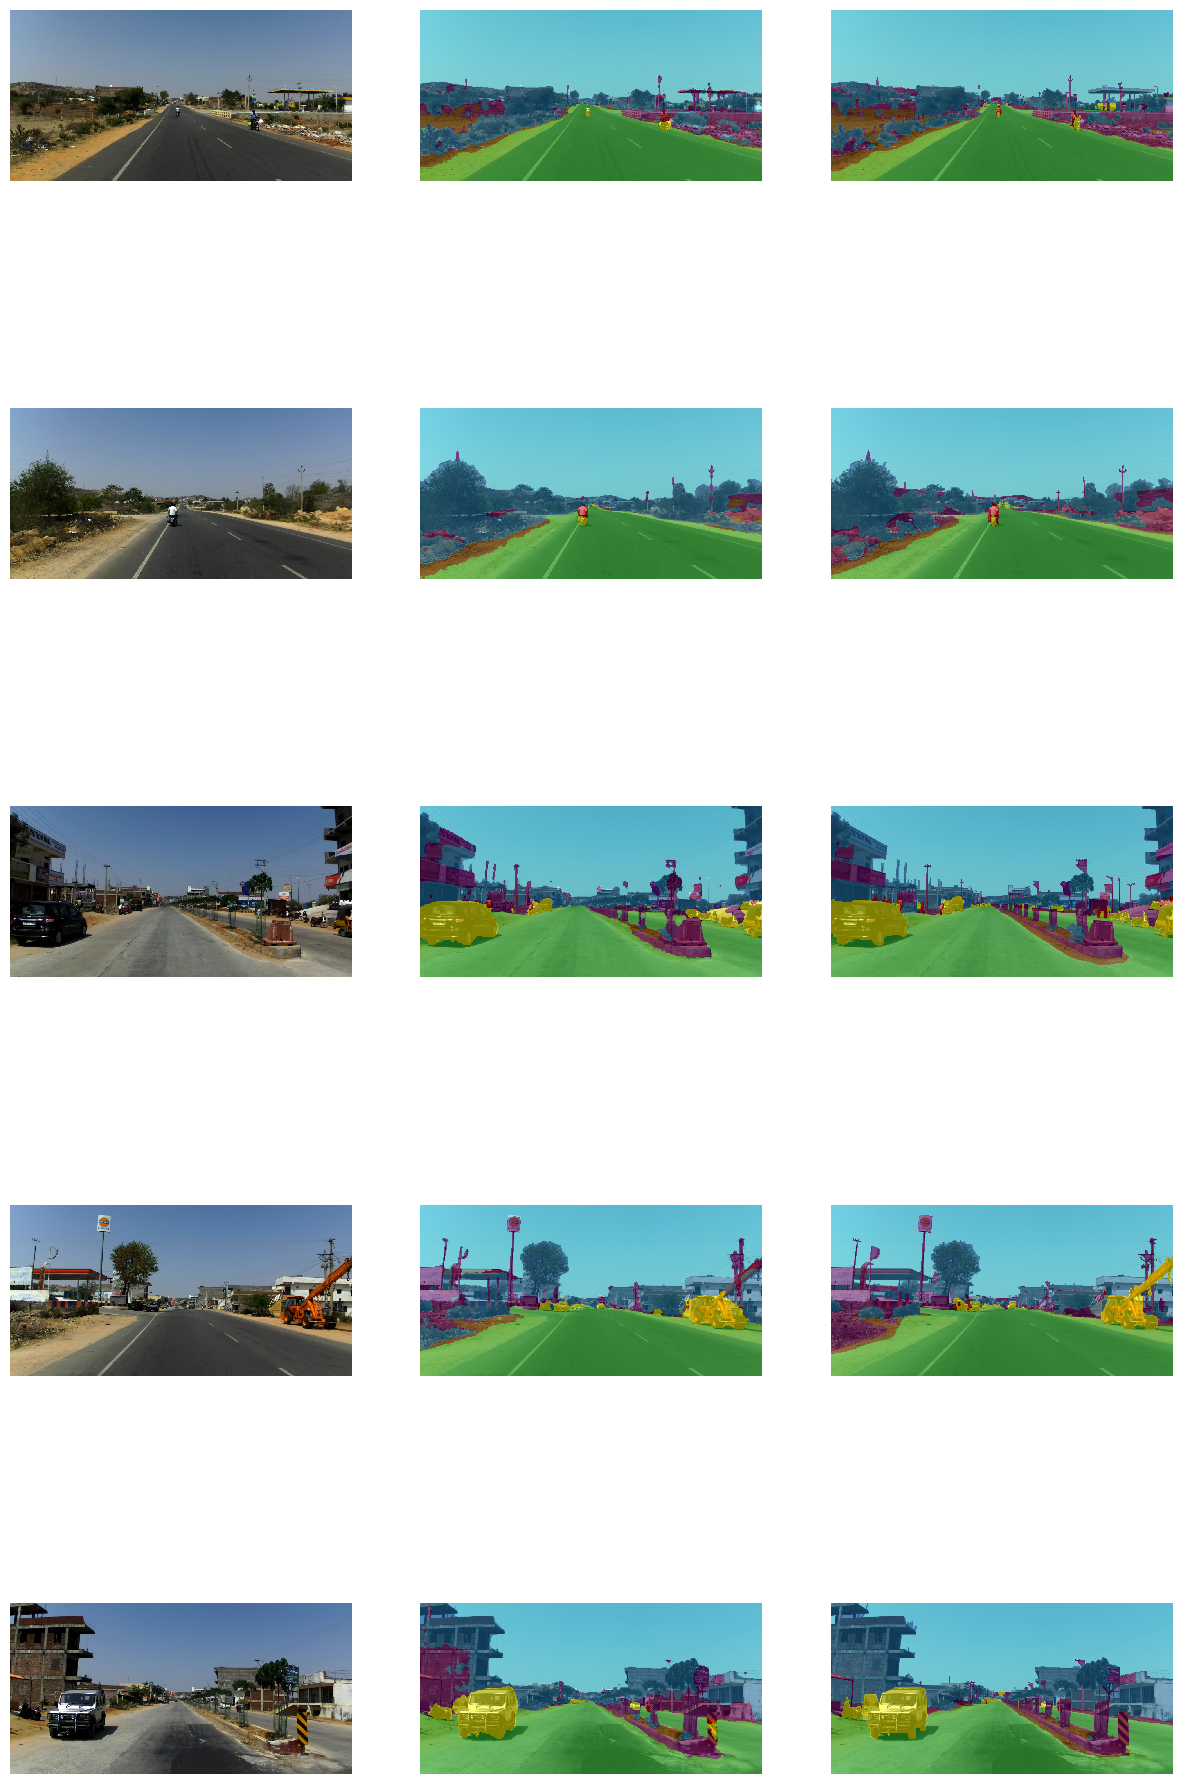

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

INFO: `Trainer.fit` stopped: `max_epochs=80` reached.


In [56]:
# model_b1_prt = torch.load("/kaggle/input/efficientvit-checkpoint/EfficientVit_supv_608_1216_80_ep_samecrop_data2_lab0125.pth")

lit_model_b1 = LitSegSemiSupervised(
    seg_model=model_b1,
    train_lab_loader=train_lab_loader_sst,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    level_mapping=HIGH_LEVEL_MAPPING,
    strong_transform_st=strong_transform_st,
    pre_strong_transform_sst=pre_strong_transform_sst,
    post_strong_transform_sst=post_strong_transform_sst,
    weak_transform_i=weak_transform_i,
    weak_transform_ii=weak_transform_ii,
    inference_transform=inference_transform,
    output_epoch=7,
    num_warmup_epochs=8,
    mu=5,
    confidence_threshold=0.95,
    weights=None,
    weighting="laplace"
)

# Initialize a model checkpoint callback
checkpoint_callback = ModelCheckpoint(
    monitor='max_val_mIoU',
    dirpath='/kaggle/working/checkpoints',
    filename='EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5-{epoch:02d}-{max_val_mIoU:.5f}',
    save_last=True,
    save_top_k=1,
    mode='max',
)

# Define the early stopping callback when mIoU has stopped improving
early_stop_callback = EarlyStopping(
    monitor="max_val_mIoU",
    min_delta=0.00,
    patience=10,
    verbose=False,
    mode="max"
)

trainer = L.Trainer(
    max_epochs=80,
    min_epochs=50,
    enable_checkpointing=True,
    callbacks=[checkpoint_callback, early_stop_callback],
    logger=TensorBoardLogger('lightning_logs', name='EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5'),
#     limit_train_batches=4,
#     limit_val_batches=88
)

iterables = {"lab": train_lab_loader_sst, "unlab": train_unlab_loader}
combined_loader = CombinedLoader(iterables, mode="min_size")
# with torch.autograd.set_detect_anomaly(True):
trainer.fit(lit_model_b1, combined_loader, val_loader, ckpt_path="/kaggle/working/last.ckpt")

In [60]:
!dir ../checkpoints

EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5-epoch=76-max_val_mIoU=0.70868.ckpt
last.ckpt


INFO: Restoring states from the checkpoint path at /kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5-epoch=74-max_val_mIoU=0.70686.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at /kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5-epoch=74-max_val_mIoU=0.70686.ckpt


Testing: |          | 0/? [00:00<?, ?it/s]

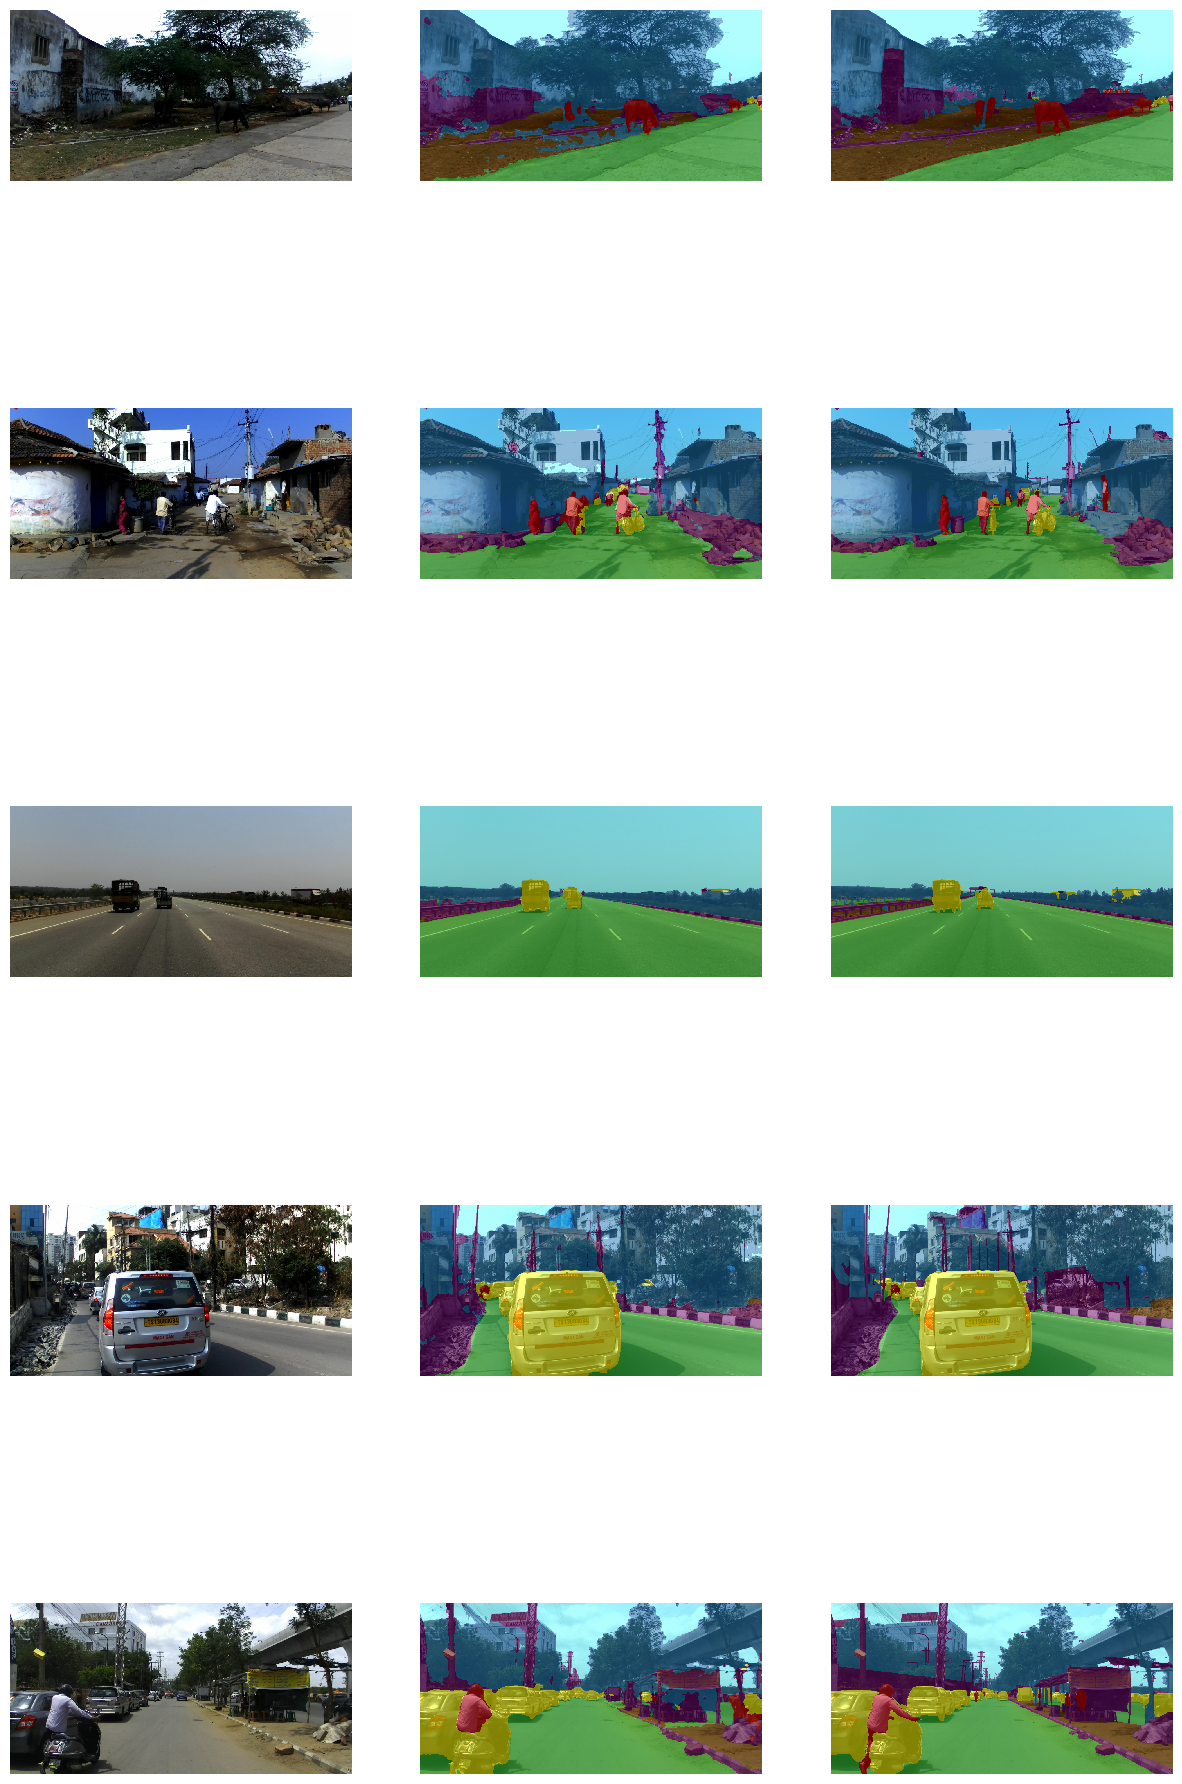

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric         ┃        DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       max_test_mIoU        │     0.7155443429946899     │
│       test_accuracy        │     0.7383472919464111     │
│  test_accuracy_teach_even  │     0.8090749382972717     │
│  test_accuracy_teach_odd   │     0.8090749382972717     │
│      test_dice_score       │     0.7588859796524048     │
│ test_dice_score_teach_even │     0.8150202035903931     │
│ test_dice_score_teach_odd  │     0.8150202035903931     │
│         test_loss          │     0.3351936340332031     │
│    test_loss_teach_even    │    0.27233633399009705     │
│    test_loss_teach_odd     │    0.27233633399009705     │
│         test_mIoU          │     0.6525865793228149     │
│    test_mIoU_teach_even    │     0.7155443429946899     │
│    test_mIoU_teach_odd     │     0.7155443429946899     │
│       test_precision       │     0.8076354265213013     │
│ test_precision_teach_even  │     0.824066162109375      │
│  test_precision_teach_odd  │     0.824066162109375      │
│        test_recall         │     0.7383472919464111     │
│   test_recall_teach_even   │     0.8090749382972717     │
│   test_recall_teach_odd    │     0.8090749382972717     │
└────────────────────────────┴────────────────────────────┘

[{'test_loss': 0.3351936340332031,
  'test_mIoU': 0.6525865793228149,
  'test_precision': 0.8076354265213013,
  'test_recall': 0.7383472919464111,
  'test_accuracy': 0.7383472919464111,
  'test_dice_score': 0.7588859796524048,
  'test_loss_teach_even': 0.27233633399009705,
  'test_mIoU_teach_even': 0.7155443429946899,
  'test_precision_teach_even': 0.824066162109375,
  'test_recall_teach_even': 0.8090749382972717,
  'test_accuracy_teach_even': 0.8090749382972717,
  'test_dice_score_teach_even': 0.8150202035903931,
  'test_loss_teach_odd': 0.27233633399009705,
  'test_mIoU_teach_odd': 0.7155443429946899,
  'test_precision_teach_odd': 0.824066162109375,
  'test_recall_teach_odd': 0.8090749382972717,
  'test_accuracy_teach_odd': 0.8090749382972717,
  'test_dice_score_teach_odd': 0.8150202035903931,
  'max_test_mIoU': 0.7155443429946899}]

In [ ]:
trainer.test(lit_model_b1, test_loader, ckpt_path="/kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5-epoch=74-max_val_mIoU=0.70686.ckpt")

In [57]:
!zip -r /kaggle/working/lightning_logs.zip /kaggle/working/efficientvit/lightning_logs

  adding: kaggle/working/efficientvit/lightning_logs/ (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5/ (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5/version_0/ (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5/version_0/hparams.yaml (stored 0%)
  adding: kaggle/working/efficientvit/lightning_logs/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5/version_0/events.out.tfevents.1723993944.ce0ffa3461d1.34.0 (deflated 73%)


In [58]:
# !dir ../checkpoints

EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt3-epoch=50-max_val_mIoU=0.70401.ckpt
last.ckpt


In [58]:
!zip -r /kaggle/working/checkpoints.zip /kaggle/working/checkpoints

  adding: kaggle/working/checkpoints/ (stored 0%)
  adding: kaggle/working/checkpoints/last.ckpt (deflated 8%)
  adding: kaggle/working/checkpoints/EViT_ss_fnt_80ep_2_teach_ema_099_5e-4_2e-3_wrmp8__laplace_weighting_data2_lab0125_608x1216_mu5_prt5-epoch=74-max_val_mIoU=0.70686.ckpt (deflated 8%)


In [ ]:
# define the LightningModule
class LitGTA(LitSegSupervised):
    def __init__(
        self,
        seg_model,
        train_lab_loader,
        val_dataset,
        test_dataset,
        level_mapping,
        strong_transform_st,
        pre_strong_transform_sst,
        post_strong_transform_sst,
        weak_transform_i,
        weak_transform_ii,
        inference_transform,
        confidence_threshold=0.5,
        mu=5,
        output_epoch=1,
        num_warmup_epochs=2,
        row_num=5,
        criterion = nn.CrossEntropyLoss,
        cmap=HIGH_CMAP,
        norm=HIGH_NORM,
        std_img=STD_TRN,
        mean_img=MEAN_TRN,
        decay_val=DECAY_VAL,
        weights=CLASS_WEIGHTS
    ):
        super().__init__(
            seg_model,
            train_lab_loader,
            val_dataset,
            test_dataset,
            level_mapping,
            strong_transform=strong_transform_st,
            inference_transform=inference_transform,
            output_epoch=output_epoch,
            num_warmup_epochs=num_warmup_epochs,
            row_num=row_num,
            criterion=criterion,
            cmap=cmap,
            norm=norm,
            std_img=std_img,
            mean_img=mean_img,
            weights=weights
        )
        
        self.teacher = deepcopy(self.seg_model).to("cuda")
        self.gta_module = deepcopy(self.seg_model).to("cuda")
        
        self.pre_strong_aug_sst = pre_strong_transform_sst
        self.post_strong_aug_sst = post_strong_transform_sst
        self.weak_aug_i = weak_transform_i
        self.weak_aug_ii = weak_transform_ii
        self.thr = confidence_threshold # currently not used
        self.mu = mu
        self.alpha_max = decay_val
        
        self.criterion_ul = criterion(reduction='none', weight=weights.float(), ignore_index=self.ignored_index)
        self.mean_iou_ul = MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.dice_ul = Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.precision_ul = MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.recall_ul = MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
        self.accuracy_ul = MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)

        # 0 - teacher_even valid, 1 - teacher_odd valid
        self.mean_iou_teach = nn.ModuleList([
            MulticlassJaccardIndex(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)\
            for _ in range(2)
        ])
        self.dice_teach = nn.ModuleList([
            Dice(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(2)
        ])
        self.precision_teach = nn.ModuleList([
            MulticlassPrecision(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(2)
        ])
        self.recall_teach = nn.ModuleList([
            MulticlassRecall(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(2)
        ])
        self.accuracy_teach = nn.ModuleList([
            MulticlassAccuracy(num_classes=self.num_classes+1, average='macro', ignore_index=self.ignored_index)
            for _ in range(2)
        ])

        self.automatic_optimization = False
        
#     def on_train_epoch_start(self):
#         if self.current_epoch % 2 == 0:
#             self.current_teacher = self.teacher_even
#             self.current_main_aug = self.cut_mix
#         else:
#             self.current_teacher = self.teacher_odd
#             self.current_main_aug = self.class_mix


    def training_step(self, batch, batch_idx):
        lab_batch, unlab_batch = batch['lab'], batch['unlab']
        optimizer_student, optimizer_gta = self.optimizers()
 
        # Unsupervised part
        optimizer_gta.zero_grad()
        
        x_unlab, _ = unlab_batch
        unlab_batch_size = x_unlab.shape[0]
        with torch.no_grad():
            x_unlab = self.weak_aug_i(x_unlab)
            x_weak = self.weak_aug_ii(x_unlab)

            self.teacher.eval()
            teacher_logits = self.teacher(x_weak)

            class_num = teacher_logits.shape[1]
            if teacher_logits.shape[2:] != x_unlab.shape[2:]:
                teacher_logits = F.interpolate(teacher_logits, size=x_unlab.shape[2:], mode='bicubic', align_corners=False)

            y_unlab = torch.softmax(teacher_logits, dim=1) # predicted teacher probabilities
            # currently testing option of using logits instead

            pixel_conf, pseudo_labels = torch.max(y_unlab, dim=1)
            x_unlab, pseudo_labels, pixel_conf = self.pre_strong_aug_sst(x_unlab, Mask(pseudo_labels), Mask(pixel_conf)) # y_unlab is N x C x H x W
            x_unlab_aug, y_unlab_aug, pixel_conf = self.current_main_aug(x_unlab, pseudo_labels, pixel_conf, unlab_batch_size)
            x_unlab_aug, y_unlab_aug, pixel_conf = self.post_strong_aug_sst(x_unlab_aug, Mask(y_unlab_aug), Mask(pixel_conf))

            weights = calculate_pixel_weights(pixel_conf, tau=1.0, percent_filtered=20)
            mean_ratio_of_confid_pix = torch.mean(pixel_conf).item()

        logits_unlab = self.gta_module(x_unlab_aug)
        if logits_unlab.shape[2:] != y_unlab_aug.shape[1:]:
            logits_unlab = F.interpolate(logits_unlab, size=y_unlab_aug.shape[1:], mode='bicubic', align_corners=False)

        unlabeled_loss = self.criterion_ul(
            logits_unlab,
            y_unlab_aug # pseudo-labels
        )

        unlabeled_loss = torch.mean(unlabeled_loss * weights.flatten()) # unlabeled_loss = torch.mean(unlabeled_loss) 
        pred_labels_unlab = logits_unlab.argmax(dim=1)
        self.manual_backward(unlabeled_loss)
        optimizer_gta.step()
        LitSegSemiSupervised.update_ema_parameters(
            self.seg_model, self.gta_module, self.get_decay(self.current_batch_idx), update_backbone_only=True
        )
        
        # Supervised part
        optimizer_student.zero_grad()
        
        x_lab, y_lab = lab_batch
        lab_batch_size = x_lab.shape[0]
        with torch.no_grad():
            y_lab = Mask(y_lab)
            x_lab, y_lab = self.strong_aug(x_lab, y_lab)
            y_lab = y_lab.long()
        logits_lab = self(x_lab)
        # Upsample logits if necessary
        if logits_lab.shape[2:] != y_lab.shape[1:]:
            logits_lab = F.interpolate(logits_lab, size=y_lab.shape[1:], mode='bicubic', align_corners=False)
        labeled_loss = self.criterion(logits_lab, y_lab)
        pred_labels_lab = logits_lab.argmax(dim=1)
        
        self.manual_backward(labeled_loss)
        optimizer_student.step()
        LitSegSemiSupervised.update_ema_parameters(
            self.teacher, self.seg_model, self.get_decay(self.current_batch_idx)
        )

        self.mean_iou[0](pred_labels_lab, y_lab)
        self.precision[0](pred_labels_lab, y_lab)
        self.recall[0](pred_labels_lab, y_lab)
        self.accuracy[0](pred_labels_lab, y_lab)
        self.dice[0](pred_labels_lab, y_lab)
        
        self.mean_iou_ul(pred_labels_unlab, y_unlab_aug)
        self.precision_ul(pred_labels_unlab, y_unlab_aug)
        self.recall_ul(pred_labels_unlab, y_unlab_aug)
        self.accuracy_ul(pred_labels_unlab, y_unlab_aug)
        self.dice_ul(pred_labels_unlab, y_unlab_aug)

        # Logging several times, since labeled and unlabeled batch sizes are different
        self.log_dict({
            'train_total_loss': total_loss
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True)
        self.log_dict({
            'train_labeled_loss': labeled_loss,
            'train_mIoU_lab': self.mean_iou[0],
            'train_precision_lab': self.precision[0],
            'train_recall_lab': self.recall[0],
            'train_accuracy_lab': self.accuracy[0],
            'train_dice_score_lab': self.dice[0]
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True, batch_size=lab_batch_size)
        self.log_dict({
            'train_unlabeled_loss': unlabeled_loss,
            'quant_of_img_passed_thr': mean_ratio_of_confid_pix,
            'train_mIoU_unlab': self.mean_iou_ul,
            'train_precision_unlab': self.precision_ul,
            'train_recall_unlab': self.recall_ul,
            'train_accuracy_unlab': self.accuracy_ul,
            'train_dice_score_unlab': self.dice_ul                                                #!!!!!!!!!!
            }, on_step=True, on_epoch=True, prog_bar=True, logger=True, batch_size=unlab_batch_size) # replaced unlab_batch_size

        self.current_batch_idx = batch_idx
        return total_loss


    def validation_step(self, batch, batch_idx):
        x, y = batch
        y = Mask(y)
        x, y = self.inference_transform(x, y)
        y = y.long()
        logits_student = self(x)
        # Upsample logits if necessary
        if logits_student.shape[2:] != y.shape[1:]:
            logits_student = F.interpolate(logits_student, size=y.shape[1:], mode='bicubic', align_corners=False)
        loss = self.criterion(logits_student, y)
        pred_labels = logits_student.argmax(dim=1)

        self.mean_iou[1](pred_labels, y)
        self.precision[1](pred_labels, y)
        self.recall[1](pred_labels, y)
        self.accuracy[1](pred_labels, y)
        self.dice[1](pred_labels, y)

        self.log_dict({
            'val_loss': loss, 
            'val_mIoU': self.mean_iou[1],
            'val_precision': self.precision[1],
            'val_recall': self.recall[1],
            'val_accuracy': self.accuracy[1],
            'val_dice_score': self.dice[1],
            }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

        del logits_student, loss, pred_labels
        torch.cuda.empty_cache()

        for idx, model, name in zip(range(2),
                                      (self.gta_module, self.teacher),
                                      ("gta_module", "teacher")):
            
            with torch.no_grad():
                model.eval()
                teacher_logits = model(x)

            # Upsample logits if necessary
            if teacher_logits.shape[2:] != y.shape[1:]:
                teacher_logits = F.interpolate(teacher_logits, size=y.shape[1:], mode='bicubic', align_corners=False)
            loss = self.criterion(teacher_logits, y)
            pred_labels = teacher_logits.argmax(dim=1)

            self.mean_iou_teach[idx](pred_labels, y)
            self.precision_teach[idx](pred_labels, y)
            self.recall_teach[idx](pred_labels, y)
            self.accuracy_teach[idx](pred_labels, y)
            self.dice_teach[idx](pred_labels, y)

            self.log_dict({
                f'val_loss_{name}': loss, 
                f'val_mIoU_{name}': self.mean_iou_teach[idx],
                f'val_precision_{name}': self.precision_teach[idx],
                f'val_recall_{name}': self.recall_teach[idx],
                f'val_accuracy_{name}': self.accuracy_teach[idx],
                f'val_dice_score_{name}': self.dice_teach[idx],
                }, on_step=False, on_epoch=True, prog_bar=True, logger=True)

            del teacher_logits, loss, pred_labels
            torch.cuda.empty_cache()
    

    def configure_optimizers(self):
        params_student = list(self.seg_model.named_parameters())
        params_gta = list(self.gta_module.named_parameters())
        
        def is_backbone(n): return 'backbone' in n

        grouped_parameters_student = [
            {"params": [p for n, p in params_student if is_backbone(n)], 'lr': 5e-4},#5e-4
            {"params": [p for n, p in params_student if not is_backbone(n)], 'lr': 2e-3},#2e-3
        ]
        
        grouped_parameters_gta = [
            {"params": [p for n, p in params_gta if is_backbone(n)], 'lr': 5e-4},#5e-4
            {"params": [p for n, p in params_gta if not is_backbone(n)], 'lr': 2e-3},#2e-3
        ]

        optimizer_student = torch.optim.AdamW(
            grouped_parameters_student, weight_decay=1e-4
        )
        
        optimizer_gta = torch.optim.AdamW(
            grouped_parameters_gta, weight_decay=1e-4
        )
        
        num_warmup_steps = self.num_warmup_epochs * self.train_loader_len
        num_training_steps = self.trainer.max_epochs * self.train_loader_len
        scheduler_student = get_cosine_schedule_with_warmup(optimizer_student, num_warmup_steps, num_training_steps)
        scheduler_gta = get_cosine_schedule_with_warmup(optimizer_gta, num_warmup_steps, num_training_steps)
        
        return (
            {"optimizer": optimizer_student,
             "lr_scheduler": scheduler_student},
            {"optimizer": optimizer_gta,
             "lr_scheduler": scheduler_gta}
        )


    def cut_mix(self, x_unlab, pseudo_labels, pixel_conf, unlab_batch_size, threshold=0.95):
        x_unlab_aug, pseudo_labels_aug = x_unlab.clone(), pseudo_labels.clone()
        shuff_idx = torch.randperm(unlab_batch_size).detach().to(self.device) # permutation indexes
        # Line of the code below won't work correctly together with affine transformations
        mean_conf = torch.mean(pixel_conf, dim=(1,2)).detach() # mean confidence for each image in a batch
        
        x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff, mean_conf_shuff =\
            x_unlab[shuff_idx], pseudo_labels[shuff_idx], pixel_conf[shuff_idx], mean_conf[shuff_idx]
        
        neg_sqrt_lambda_arr = torch.sqrt(1 - (mean_conf / (mean_conf + mean_conf_shuff)))

        r_y = torch.randint(
            low=0, high=x_unlab.shape[2], size=(unlab_batch_size,), device=self.device, dtype=torch.int32
        ).detach()
        r_x = torch.randint(
            low=0, high=x_unlab.shape[3], size=(unlab_batch_size,), device=self.device, dtype=torch.int32
        ).detach()
        r_h = (x_unlab.shape[2] * neg_sqrt_lambda_arr).detach()
        r_w = (x_unlab.shape[3] * neg_sqrt_lambda_arr).detach()

        x_left = torch.max(r_x - r_w/2, torch.tensor(0).to(self.device).detach()).round().int()
        x_right = torch.min(r_x + r_w/2, torch.tensor(x_unlab.shape[3]).to(self.device).detach()).round().int()
        y_up = torch.max(r_y - r_h/2, torch.tensor(0).to(self.device).detach()).round().int()
        y_down = torch.min(r_y + r_h/2, torch.tensor(x_unlab.shape[2]).to(self.device).detach()).round().int()

        for idx in range(unlab_batch_size):
            x_unlab_aug[idx, :, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                x_unlab_shuff[idx, :, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
            pseudo_labels_aug[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                pseudo_labels_shuff[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]
            pixel_conf[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]] =\
                pixel_conf_shuff[idx, y_up[idx]:y_down[idx], x_left[idx]:x_right[idx]]

        del x_unlab, pseudo_labels, x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff,\
            mean_conf_shuff, shuff_idx, mean_conf, neg_sqrt_lambda_arr, r_y, r_x, r_h, r_w,\
            x_left, x_right, y_up, y_down
        torch.cuda.empty_cache()

        return x_unlab_aug, pseudo_labels_aug, pixel_conf


    def class_mix(self, x_unlab, pseudo_labels, pixel_conf, unlab_batch_size, threshold=0.95):
        shuff_idx = torch.randperm(unlab_batch_size).detach().to(self.device) # permutation indexes
        x_unlab_shuff, pseudo_labels_shuff, pixel_conf_shuff =\
            x_unlab[shuff_idx], pseudo_labels[shuff_idx], pixel_conf[shuff_idx]

        for idx in range(unlab_batch_size):
            img_classes = torch.unique(pseudo_labels_shuff[idx])

            classes_quant = img_classes.size(dim=0)
            chosen_classes = img_classes[torch.argsort(torch.randperm(classes_quant, dtype=torch.int32, device=DEVICE))[:int(classes_quant/2)]]

            mask = torch.isin(pseudo_labels_shuff[idx], chosen_classes).long() # removed detach()
            pseudo_labels[idx] = pseudo_labels[idx] * (1 - mask) + pseudo_labels_shuff[idx] * mask
            pixel_conf[idx] = pixel_conf[idx] * (1 - mask) + pixel_conf_shuff[idx] * mask
            
            mask = mask.unsqueeze(0)
            x_unlab[idx] = x_unlab[idx] * (1 - mask) + x_unlab_shuff[idx] * mask
        
        del pseudo_labels_shuff, pixel_conf_shuff, shuff_idx, img_classes,\
            chosen_classes, x_unlab_shuff
        torch.cuda.empty_cache()
        
        return x_unlab, pseudo_labels, pixel_conf


    def get_decay(self, batch_idx):
        # dynema
#         return np.minimum(batch_idx / (batch_idx + 1), self.alpha_max) # stop increasing after batch 100
        # linrampema
#         return self.current_epoch / self.trainer.max_epochs * self.alpha_max
        # lindeclineema
#         return np.maximum(1 -  (self.current_epoch + 1) / self.trainer.max_epochs * (1 - self.alpha_max), self.alpha_max)
        return np.maximum(1 -  (self.current_epoch * self.trainer.num_training_batches + batch_idx + 1) / (self.trainer.num_training_batches * self.trainer.max_epochs) * (1 - self.alpha_max), self.alpha_max)

    @staticmethod
    def calculate_pixel_weights(pixel_conf, tau, percent_filtered):
        # Move the tensor to CPU and convert to NumPy array for percentile calculation
        conf_np = pixel_conf.cpu().numpy().flatten()
        # Calculate the 20th percentile
        conf_thresh = np.percentile(conf_np, percentile)
        # Create a boolean mask where confidence values are less than or equal to the threshold
        mask = pixel_conf.ge(conf_thresh).float()
        # Calculate the numerator for the weight formula
        conf_plus_tau = torch.add(pixel_conf, tau)
        numerator = conf_plus_tau * mask * mask.sum()
        # Calculate the denominator for the weight formula
        denominator = (conf_plus_tau * mask).sum()
        # Calculate the weights
        weights = numerator / denominator

        return weights